 # <span style="color:darkred">Sinarmasland Non-Performing Invoice (NPI/IPL) and Billing Analysis  </span>

# <span style="color:darkred">01. BUSINESS CONTEXT</span>

Township Management memiliki peran penting dalam menjaga kelancaran operasional kawasan perumahan, termasuk mengelola iuran pengelolaan lingkungan (IPL), penagihan utilitas, dan layanan terkait properti.

Salah satu tanggung jawab operasional utama adalah memastikan penagihan IPL tepat waktu guna mendukung keberlanjutan keuangan operasional perumahan. Proses penagihan dan penagihan yang efektif, didukung oleh catatan pembayaran yang akurat dan informasi pemilik unit yang andal, sangat penting untuk menjaga arus kas operasional.

Seiring bertambahnya jumlah unit yang dikelola, pemantauan kinerja pembayaran, identifikasi tagihan yang belum dibayar, dan pemeliharaan konsistensi data menjadi semakin penting bagi manajemen keuangan dan operasional yang efektif.

Proyek ini berfokus pada analisis data tagihan dan penagihan IPL untuk memberikan insight mengenai tagihan yang Belum Dibayar (NPI), mengidentifikasi faktor-faktor yang berpotensi menjadi penyebabnya, serta mendukung pengambilan keputusan berbasis data bagi Township Management.

# <span style="color:darkred">02. PROBLEM STATEMENT</span>

Township Management menghadapi tantangan besar dalam mengelola invoices yang tidak terbayar (NPI), khususnya pembayaran IPL yang tertunggak, yang diperkirakan melebihi 25% dari total faktur aktif berdasarkan gabungan status “Unpaid” dan “Outstanding”.

Meningkatnya volume invoice yang tertunggak berpotensi menimbulkan tekanan keuangan pada operasional township dan dapat meningkatkan ketergantungan pada subsidi perusahaan induk jika tidak ditangani dengan tepat dalam dua kuartal ke depan.

Beberapa faktor operasional dan terkait data memerlukan penyelidikan lebih lanjut:

*   ```Vacant Units:``` Sejumlah unit hunian tetap kosong dalam jangka waktu yang lama, namun kontribusinya terhadap total IPL yang belum dibayar belum diidentifikasi dengan jelas.
*   ```Efektivitas Penagihan / Collection Effectiveness:``` Informasi kontak pemilik yang tidak lengkap dapat membatasi efektivitas upaya penagihan dalam menjangkau pemilik unit yang menunggak.
*   ```Standarisasi Metode Pembayaran:``` Penamaan metode pembayaran yang tidak konsisten dalam sistem penagihan menimbulkan tantangan dalam pelacakan pembayaran dan rekonsiliasi keuangan bulanan.
*   ```Kualitas Data Penagihan:``` Kekosongan dalam pencatatan penggunaan air dan dokumentasi penagihan dapat memengaruhi keakuratan dan keandalan data penagihan operasional.

Tantangan-tantangan ini menyoroti perlunya penilaian berbasis data untuk mengidentifikasi kontributor utama NPI, mengevaluasi pola penagihan dan pembayaran, serta meningkatkan kualitas informasi yang digunakan oleh tim Penagihan, Keuangan, dan Manajemen Aset.

# <span style="color:darkred">03. PROJECT OBJECTIVES</span>

```Mengidentifikasi Tren NPI dan Faktor-Faktor Utama yang Memengaruhi Terjadinya NPI```

Menganalisis tren NPI, jumlah tunggakan, serta karakteristik unit atau cluster untuk mengidentifikasi segmen yang memberikan kontribusi paling signifikan terhadap tunggakan IPL.

```Mengevaluasi Kontribusi Unit Kosong / vacant```

Menilai kontribusi unit-unit yang kosong dalam jangka panjang terhadap total NPI serta memeriksa potensi ketidakteraturan dalam catatan penggunaan air dan penagihan mereka.

```Menilai Efektivitas Penagihan```

Memeriksa pola tindakan penagihan, respons pembayaran, dan frekuensi pengingat untuk mengidentifikasi peluang dalam meningkatkan strategi penagihan.

```Menganalisis Metode Pembayaran dan Kualitas Data```

Mengevaluasi pemanfaatan metode pembayaran, mengidentifikasi inconsistencies pada penamaan, serta menilai kelengkapan informasi kontak pemilik unit dan catatan penagihan.

*Temuan ini akan digunakan untuk menyusun rekomendasi yang dapat ditindaklanjuti guna mendukung prioritas penagihan, perbaikan proses pembayaran, dan pengelolaan data yang lebih baik di seluruh tim operasional yang relevan.*

# <span style="color:darkred">04. BUSINESS QUESTIONS</span>

```NPI Overview & Segmentation```
*   How Does the NPI rate and outstanding amount trend over the billing period?
*   Which unit characteristics and clusters contribute the most to outstanding IPL?

```Vacant Unit & Water Billing```
*   How significant is the contribution of vacant units to total NPI?
*   Are there unusual water usage patterns or billing records among vacant units?

```Collection Effectiveness```
*   Which collection actions types are associated with the highest successful payment responses?
*   How does reminder frequency relate to invoice payment status?

```Payment & Data Quality```
*   What are the most frequently used payment methods, and what naming inconsistencies need standardization?
*   How many outstanding invoices are associated with units that have incomplete or unverified owner contact information?



# <span style="color:darkred">05. DATA EXTRACT & UNDERSTANDING</span>

In [67]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import seaborn as sns

# Utilities
import os
import warnings

warnings.filterwarnings('ignore')

In [1]:
from google.colab import files
import pandas as pd
import io

# Upload multiple files from local files
uploaded = files.upload()

Saving sml_units.csv to sml_units.csv
Saving sml_collection_actions.csv to sml_collection_actions.csv
Saving sml_ipl_billings.csv to sml_ipl_billings.csv
Saving sml_clusters.csv to sml_clusters.csv
Saving sml_payment_disputes.csv to sml_payment_disputes.csv


In [2]:
# Load datasets
datasets = {}

for filename in uploaded.keys():
    datasets[filename.replace('.csv', '')] = pd.read_csv(io.BytesIO(uploaded[filename]))

In [13]:
# Create new dictionary mapping clean names to the actual loaded DataFrames from datasets
dfs = {
    'clusters': datasets['sml_clusters'],
    'units': datasets['sml_units'],
    'ipl_billings': datasets['sml_ipl_billings'],
    'collections': datasets['sml_collection_actions'],
    'payment_disputes': datasets['sml_payment_disputes'],
}

# Sekarang kita lakukan loop menggunakan nama-nama baru
for name, df in dfs.items():
    print(f"\n{'=' * 100}")
    print(f"{name}  |  {len(df):,} baris, {df.shape[1]} kolom")
    print('=' * 100)
    display(df.head())


clusters  |  111 baris, 8 kolom


,cluster_id,township_name,cluster_category,launch_phase,facility_tier,zone_type,handover_completion_pct,management_office_distance_category
0,CLS-BSD-18-01,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite
1,CLS-BSD-18-02,BSD City,Middle Residential,2018-2020 (Established),Plus,Residential Core,99.4,Regional Hub
2,CLS-BSD-18-03,BSD City,Middle Residential,2018-2020 (Established),Plus,Residential Core,87.6,Regional Hub
3,CLS-BSD-18-04,BSD City,Commercial Ruko,2018-2020 (Established),Standard,Commercial Ring,90.6,Regional Hub
4,CLS-BSD-18-05,BSD City,Middle Residential,2018-2020 (Established),Plus,Mixed,96.5,Onsite



units  |  28,881 baris, 11 kolom


,unit_id,cluster_id,owner_name,contact_number,owner_domicile,is_vacant,unit_size_m2,ipl_base_fee,handover_date,unit_type,contact_verified
0,UNT-BSD1801-0001,CLS-BSD-18-01,Bambang Halim,8.820534e+09,Dalam Kota,False,115.5,500000,2019-05-24,Rumah Tapak,True
1,UNT-BSD1801-0002,CLS-BSD-18-01,Fajar Winata,8.146846e+09,Dalam Kota,False,90.5,350000,2018-12-15,Rumah Tapak,False
2,UNT-BSD1801-0003,CLS-BSD-18-01,Joko Permadi,8.544454e+09,Luar Kota,True,126.4,500000,2018-11-10,Rumah Tapak,True
3,UNT-BSD1801-0004,CLS-BSD-18-01,Sinta Suryadi,8.309106e+09,Dalam Kota,False,105.3,500000,2019-11-19,Rumah Tapak,True
4,UNT-BSD1801-0005,CLS-BSD-18-01,Hesti Tanuwijaya,8.742370e+09,Dalam Kota,False,104.6,500000,2018-09-17,Rumah Tapak,True



ipl_billings  |  807,427 baris, 15 kolom


,invoice_id,unit_id,billing_month,water_usage_m3,water_meter_input_method,ipl_base_fee,late_fee_penalty,total_amount,payment_status,payment_method,payment_date,due_date,billing_channel,reminder_sent_count,is_autodebit_enrolled
0,INV/BSD/202207/00001,UNT-BSD1801-0001,2022-07,24.9,Manual,500000,0,686750.0,Overdue,NaN,NaN,2022-08-07,SMS Blast,3,False
1,INV/BSD/202208/00001,UNT-BSD1801-0001,2022-08,25.2,Manual,500000,20000,709000.0,Overdue,NaN,NaN,2022-09-08,Portal Online App,1,False
2,INV/BSD/202209/00001,UNT-BSD1801-0001,2022-09,19.8,Manual,500000,30000,678500.0,Overdue,NaN,NaN,2022-10-08,Portal Online App,4,False
3,INV/BSD/202210/00001,UNT-BSD1801-0001,2022-10,19.1,Manual,500000,0,643250.0,Paid,Cash,2022-10-11,2022-11-12,SMS Blast,1,True
4,INV/BSD/202211/00001,UNT-BSD1801-0001,2022-11,16.6,Manual,500000,0,624500.0,Paid,toped,2022-11-04,2022-12-13,Portal Online App,1,False



collections  |  126,772 baris, 7 kolom


,action_id,invoice_id,unit_id,action_date,action_type,agent_id,response_status
0,TKT-JKT-20220817-0001,INV/BSD/202208/00001,UNT-BSD1801-0001,2022-08-17,Telepon,AG-JKT-006,Janji Bayar
1,TKT-JKT-20230826-0001,INV/BSD/202308/00003,UNT-BSD1801-0003,2023-08-26,Telepon,AG-JKT-003,Tidak Respon
2,TKT-JKT-20231220-0001,INV/BSD/202312/00003,UNT-BSD1801-0003,2023-12-20,Telepon,AG-JKT-006,Tidak Respon
3,TKT-JKT-20240127-0001,INV/BSD/202401/00003,UNT-BSD1801-0003,2024-01-27,Telepon,AG-JKT-002,Tidak Respon
4,TKT-JKT-20240427-0001,INV/BSD/202404/00005,UNT-BSD1801-0005,2024-04-27,Telepon,AG-JKT-001,Tidak Respon



payment_disputes  |  23,928 baris, 9 kolom


,dispute_id,invoice_id,unit_id,dispute_date,dispute_channel,dispute_reason,resolution_status,days_to_resolve,amount_adjusted
0,DSP/220704/9538,INV/GWS/202207/02103,UNT-GWS2008-0111,2022-07-04,Call Center,Kesalahan Nominal Lainnya,Diproses,NaN,NaN
1,DSP/220704/9786,INV/BSD/202207/02549,UNT-BSD1909-0083,2022-07-04,Kantor Pengelola,Kesalahan Nominal Lainnya,Dibatalkan - Tagihan Salah,3.0,1062250.0
2,DSP/220704/7272,INV/DLT/202207/00466,UNT-DLT1903-0280,2022-07-04,Call Center,Sudah Bayar Tapi Tercatat Belum Lunas,Ditolak - Tagihan Sah,3.0,0.0
3,DSP/220704/6327,INV/KWS/202207/04881,UNT-KWS2018-0068,2022-07-04,Kantor Pengelola,Kesalahan Nominal Lainnya,Ditolak - Tagihan Sah,5.0,0.0
4,DSP/220704/3644,INV/BSD/202207/04627,UNT-BSD2119-0248,2022-07-04,Call Center,Sudah Bayar Tapi Tercatat Belum Lunas,Ditolak - Tagihan Sah,3.0,0.0


In [14]:
# Check data structure

for name, df in dfs.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    df.info()


DATASET: CLUSTERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111 entries, 0 to 110
Data columns (total 8 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   cluster_id                           111 non-null    object 
 1   township_name                        111 non-null    object 
 2   cluster_category                     111 non-null    object 
 3   launch_phase                         111 non-null    object 
 4   facility_tier                        111 non-null    object 
 5   zone_type                            111 non-null    object 
 6   handover_completion_pct              111 non-null    float64
 7   management_office_distance_category  111 non-null    object 
dtypes: float64(1), object(7)
memory usage: 7.1+ KB

DATASET: UNITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28881 entries, 0 to 28880
Data columns (total 11 columns):
 #   Column            Non-Null Count  D

In [15]:
# Identify data categorical
categorical_cols = ['township_name', 'cluster_category', 'launch_phase', 'facility_tier','zone_type', 'management_office_distance_category', 'owner_domicile','unit_type', 'billing_month','water_meter_input_method','payment_status', 'payment_method' ,'billing_channel', 'action_type', 'response_status', 'dispute_channel', 'dispute_reason','resolution_status']

for col in categorical_cols:
    # Cari dataframe di dfs yang memiliki kolom ini
    found_df = None
    for df_name, df_obj in dfs.items():
        if col in df_obj.columns:
            found_df = df_obj
            break

    if found_df is not None:
        print(f"\n--- {col.upper()} (from table: {df_name}) ---")
        display(
            found_df[col]
            .value_counts(dropna=False)
            .rename_axis(col)
            .reset_index(name='session_frequency')
        )
    else:
        print(f"\n--- {col.upper()} (Not found in any table) ---")


--- TOWNSHIP_NAME (from table: clusters) ---


,township_name,session_frequency
0,BSD City,34
1,Kota Wisata,30
2,Grand Wisata,23
3,Deltamas,15
4,NavaPark,9



--- CLUSTER_CATEGORY (from table: clusters) ---


,cluster_category,session_frequency
0,Middle Residential,67
1,Premium Residential,24
2,Commercial Ruko,16
3,Industrial/Commercial,4



--- LAUNCH_PHASE (from table: clusters) ---


,launch_phase,session_frequency
0,2018-2020 (Established),60
1,2021-2023 (New Phase),51


... (26 outputs left out)


--- DISPUTE_REASON (from table: payment_disputes) ---


,dispute_reason,session_frequency
0,Duplikat Tagihan,16767
1,Kesalahan Nominal Lainnya,2871
2,Sudah Bayar Tapi Tercatat Belum Lunas,2358
3,Pemakaian Air Tidak Wajar,1932



--- RESOLUTION_STATUS (from table: payment_disputes) ---


,resolution_status,session_frequency
0,Dibatalkan - Tagihan Salah,16610
1,Ditolak - Tagihan Sah,4596
2,Diproses,2722


# <span style="color:darkred">06. DATA CLEANING</span>

In [17]:
# Check missing values
df.isnull().sum()

# Remove duplicates
df = df.drop_duplicates()

In [19]:
# Convert date columns to datetime in each dataset
units['handover_date'] = pd.to_datetime(units['handover_date'])
ipl_billings['payment_date'] = pd.to_datetime(ipl_billings['payment_date'])
ipl_billings['due_date'] = pd.to_datetime(ipl_billings['due_date'])
collections['action_date'] = pd.to_datetime(collections['action_date'])
payment_disputes['dispute_date'] = pd.to_datetime(payment_disputes['dispute_date'])

In [20]:
for name, df in dfs.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    df.info()


DATASET: CLUSTERS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111 entries, 0 to 110
Data columns (total 8 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   cluster_id                           111 non-null    object 
 1   township_name                        111 non-null    object 
 2   cluster_category                     111 non-null    object 
 3   launch_phase                         111 non-null    object 
 4   facility_tier                        111 non-null    object 
 5   zone_type                            111 non-null    object 
 6   handover_completion_pct              111 non-null    float64
 7   management_office_distance_category  111 non-null    object 
dtypes: float64(1), object(7)
memory usage: 7.1+ KB

DATASET: UNITS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28881 entries, 0 to 28880
Data columns (total 11 columns):
 #   Column            Non-Null Count  D

In [21]:
# Columns that need inspection
columns_to_check = {
    'units': [
        'contact_number',
        'unit_size_m2',
        'handover_date'
    ],
    'ipl_billings': [
        'billing_month',
        'water_usage_m3',
        'total_amount',
        'payment_date',
        'due_date'
    ],
    'collections': [
        'action_date'
    ],
    'payment_disputes': [
        'dispute_date',
        'amount_adjusted'
    ]
}

for dataset, columns in columns_to_check.items():
    print(f"\n{'='*50}")
    print(f"{dataset.upper()}")

    for col in columns:
        print(f"\n{col}")
        print(dfs[dataset][col].head(10).tolist())


UNITS

contact_number
[8820533790.0, 8146846026.0, 8544454412.0, 8309105929.0, 8742369667.0, 8942815042.0, 8870689217.0, nan, 8147938240.0, 8668043995.0]

unit_size_m2
[115.5, 90.5, 126.4, 105.3, 104.6, 119.1, 115.6, 80.0, 72.4, 107.1]

handover_date
[Timestamp('2019-05-24 00:00:00'), Timestamp('2018-12-15 00:00:00'), Timestamp('2018-11-10 00:00:00'), Timestamp('2019-11-19 00:00:00'), Timestamp('2018-09-17 00:00:00'), Timestamp('2019-11-18 00:00:00'), Timestamp('2018-09-04 00:00:00'), Timestamp('2019-03-20 00:00:00'), Timestamp('2018-11-02 00:00:00'), Timestamp('2018-09-06 00:00:00')]

IPL_BILLINGS

billing_month
['2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12', '2023-01', '2023-02', '2023-03', '2023-04']

water_usage_m3
[24.9, 25.2, 19.8, 19.1, 16.6, 14.7, 4.1, 25.7, 17.0, 23.7]

total_amount
[686750.0, 709000.0, 678500.0, 643250.0, 624500.0, 610250.0, 530750.0, 692750.0, 627500.0, 677750.0]

payment_date
[NaT, NaT, NaT, Timestamp('2022-10-11 00:00:00'), Timestamp('2

In [22]:
# DATA TYPE CONVERSION

# 1. UNITS
units = dfs['units']

# Contact number: remove trailing .0 and keep as string
units['contact_number'] = (
    units['contact_number']
    .astype('string')
    .str.replace(r'\.0$', '', regex=True)
)

# Unit size: Decimal -> float
units['unit_size_m2'] = pd.to_numeric(
    units['unit_size_m2'],
    errors='coerce'
)

# Handover date: date -> datetime
units['handover_date'] = pd.to_datetime(
    units['handover_date'],
    errors='coerce'
)


# 2. IPL BILLINGS
billings = dfs['ipl_billings']

# Billing month: YYYY-MM -> monthly period
billings['billing_month'] = pd.to_datetime(
    billings['billing_month'],
    format='%Y-%m',
    errors='coerce'
).dt.to_period('M')

# Numeric conversion
numeric_columns = ['water_usage_m3', 'total_amount']

for col in numeric_columns:
    billings[col] = pd.to_numeric(
        billings[col],
        errors='coerce'
    )

# Date conversion
date_columns = ['payment_date', 'due_date']

for col in date_columns:
    billings[col] = pd.to_datetime(
        billings[col],
        errors='coerce'
    )


# 3. COLLECTIONS
collections = dfs['collections']

collections['action_date'] = pd.to_datetime(
    collections['action_date'],
    errors='coerce'
)


# 4. PAYMENT DISPUTES
disputes = dfs['payment_disputes']

disputes['dispute_date'] = pd.to_datetime(
    disputes['dispute_date'],
    errors='coerce'
)

disputes['amount_adjusted'] = pd.to_numeric(
    disputes['amount_adjusted'],
    errors='coerce'
)


print("Data type conversion completed!")

Data type conversion completed!


In [23]:
# Verify hasil conversion data type
for name, df in dfs.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    display(df.dtypes.to_frame(name='Data Type'))


DATASET: CLUSTERS


,Data Type
cluster_id,object
township_name,object
cluster_category,object
launch_phase,object
facility_tier,object
zone_type,object
handover_completion_pct,float64
management_office_distance_category,object



DATASET: UNITS


,Data Type
unit_id,object
cluster_id,object
owner_name,object
contact_number,string[python]
owner_domicile,object
is_vacant,bool
unit_size_m2,float64
ipl_base_fee,int64
handover_date,datetime64[ns]
unit_type,object



DATASET: IPL_BILLINGS


,Data Type
invoice_id,object
unit_id,object
billing_month,period[M]
water_usage_m3,float64
water_meter_input_method,object
ipl_base_fee,int64
late_fee_penalty,int64
total_amount,float64
payment_status,object
payment_method,object



DATASET: COLLECTIONS


,Data Type
action_id,object
invoice_id,object
unit_id,object
action_date,datetime64[ns]
action_type,object
agent_id,object
response_status,object



DATASET: PAYMENT_DISPUTES


,Data Type
dispute_id,object
invoice_id,object
unit_id,object
dispute_date,datetime64[ns]
dispute_channel,object
dispute_reason,object
resolution_status,object
days_to_resolve,float64
amount_adjusted,float64


In [24]:
# Check the contact number format already string
display(
    units[['contact_number']].head(10)
)

,contact_number
0,8820533790
1,8146846026
2,8544454412
3,8309105929
4,8742369667
5,8942815042
6,8870689217
7,<NA>
8,8147938240
9,8668043995


In [25]:
# Check the amount adjusted format already float
display(
    disputes[['amount_adjusted']].head(10)
)

,amount_adjusted
0,NaN
1,1062250.0
2,0.0
3,0.0
4,0.0
5,357500.0
6,0.0
7,510500.0
8,NaN
9,30482500.0


In [26]:
# Check missing values
for name, df in dfs.items():
    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    missing_summary = pd.DataFrame({
        'Missing Count': df.isnull().sum(),
        'Missing Percentage': (
            df.isnull().sum() / len(df) * 100
        ).round(2)
    })

    display(
        missing_summary[
            missing_summary['Missing Count'] > 0
        ]
    )


DATASET: CLUSTERS


,Missing Count,Missing Percentage



DATASET: UNITS


,Missing Count,Missing Percentage
contact_number,4978,17.24



DATASET: IPL_BILLINGS


,Missing Count,Missing Percentage
payment_method,298426,36.96
payment_date,298426,36.96



DATASET: COLLECTIONS


,Missing Count,Missing Percentage



DATASET: PAYMENT_DISPUTES


,Missing Count,Missing Percentage
days_to_resolve,2722,11.38
amount_adjusted,2722,11.38


**Missing Values** yang terdapat pada data tidak akan dihapus karena bukan merupakan kesalahan /  data quality issues. Missing values pada kolom ```payment_method``` dan ```payment_date``` terjadi karena pembayaran tagihan belum dilakukan, kemudian missing values pada kolom ```days_to_resolve``` dan ```amount_adjusted``` terjadi karena disputes masih dalam proses.

Sedangkan untuk missing values pada kolom ```contact_number``` juga tidak akan dihapus karena dapat digunakan untuk data supportif.

In [27]:
# Validate payment-related missing values

billings = dfs['ipl_billings']

payment_missing_check = pd.crosstab(
    billings['payment_status'],
    billings['payment_date'].isna(),
    margins=True
)

display(payment_missing_check)

payment_date,False,True,All
payment_status,,,
Overdue,0,199021,199021
Paid,509001,0,509001
Unpaid,0,99405,99405
All,509001,298426,807427


In [28]:
# Validate payment method missing values by status

display(
    pd.crosstab(
        billings['payment_status'],
        billings['payment_method'].isna(),
        margins=True
    )
)

payment_method,False,True,All
payment_status,,,
Overdue,0,199021,199021
Paid,509001,0,509001
Unpaid,0,99405,99405
All,509001,298426,807427


Deeper analysis untuk missing values pada kolom ```payment_method``` dan ```payment_date```.

*   Seluruh invoice dengan status ```Paid``` memiliki payment date dan payment method.
*   Seluruh invoice dengan status ```Unpaid``` dan ```Overdue``` tidak memiliki kedua informasi tersebut.
*   Pola missing values konsisten dengan business logic dan merupakan missing values tersebut merefleksikan kondisi operasional nyata dan bukan merupakan kesalahan pencatatan.

In [29]:
# Validate disputes-related missing values
disputes = dfs['payment_disputes']

dispute_missing_check = pd.crosstab(
    disputes['resolution_status'],
    disputes['days_to_resolve'].isna(),
    margins=True
)

display(dispute_missing_check)

days_to_resolve,False,True,All
resolution_status,,,
Dibatalkan - Tagihan Salah,16610,0,16610
Diproses,0,2722,2722
Ditolak - Tagihan Sah,4596,0,4596
All,21206,2722,23928


Deeper analysis untuk missing values pada kolom ```days_to_resolve``` dan ```amount_adjusted```.

Seluruh dispute yang masih berstatus ```Diproses``` belum memiliki data ```days_to_resolve``` dan ```amount_adjusted``` maka kedua kolom tersebut akan tetap dipertahankan.

**Check Duplicate**

In [30]:
# Check full duplicate dimana seluruh kolom dalam satu baris memiliki nilai yang sama
for name, df in dfs.items():

    print(f"\n{'='*50}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*50}")

    duplicate_count = df.duplicated().sum()

    print(f"Total rows       : {len(df):,}")
    print(f"Full duplicates  : {duplicate_count:,}")
    print(
        f"Duplicate percentage: "
        f"{duplicate_count / len(df) * 100:.2f}%"
    )


DATASET: CLUSTERS
Total rows       : 111
Full duplicates  : 0
Duplicate percentage: 0.00%

DATASET: UNITS
Total rows       : 28,881
Full duplicates  : 0
Duplicate percentage: 0.00%

DATASET: IPL_BILLINGS
Total rows       : 807,427
Full duplicates  : 0
Duplicate percentage: 0.00%

DATASET: COLLECTIONS
Total rows       : 126,772
Full duplicates  : 0
Duplicate percentage: 0.00%

DATASET: PAYMENT_DISPUTES
Total rows       : 23,928
Full duplicates  : 0
Duplicate percentage: 0.00%


In [31]:
# Primary key validation (makesure tidak ada double data di setiap primary key)

primary_keys = {
    'clusters': 'cluster_id',
    'units': 'unit_id',
    'ipl_billings': 'invoice_id',
    'collections': 'action_id',
    'payment_disputes': 'dispute_id'
}

for name, key in primary_keys.items():

    df = dfs[name]

    duplicate_count = df[key].duplicated().sum()

    print(f"\n{name.upper()}")
    print(f"Primary key: {key}")
    print(f"Duplicate IDs: {duplicate_count:,}")
    print(f"Unique IDs: {df[key].nunique():,}")


CLUSTERS
Primary key: cluster_id
Duplicate IDs: 0
Unique IDs: 111

UNITS
Primary key: unit_id
Duplicate IDs: 0
Unique IDs: 28,881

IPL_BILLINGS
Primary key: invoice_id
Duplicate IDs: 0
Unique IDs: 807,427

COLLECTIONS
Primary key: action_id
Duplicate IDs: 0
Unique IDs: 126,772

PAYMENT_DISPUTES
Primary key: dispute_id
Duplicate IDs: 0
Unique IDs: 23,928


*   Tidak ditemukan baris yang identik secara keseluruhan.
*   Tidak ditemukan duplikasi pada primary key masing-masing tabel.
*   Seluruh primary key memiliki jumlah unique ID yang sesuai dengan jumlah records.

In [32]:
# Check missing primary keys
for name, key in primary_keys.items():
    df = dfs[name]

    print(
        f"{name.upper()} - "
        f"Missing {key}: {df[key].isna().sum():,}"
    )

CLUSTERS - Missing cluster_id: 0
UNITS - Missing unit_id: 0
IPL_BILLINGS - Missing invoice_id: 0
COLLECTIONS - Missing action_id: 0
PAYMENT_DISPUTES - Missing dispute_id: 0


In [33]:
# Check foreign key

# Define relationships
relationships = {
    'units_to_clusters': {
        'child': 'units',
        'child_key': 'cluster_id',
        'parent': 'clusters',
        'parent_key': 'cluster_id'
    },
    'billings_to_units': {
        'child': 'ipl_billings',
        'child_key': 'unit_id',
        'parent': 'units',
        'parent_key': 'unit_id'
    },
    'collections_to_billings': {
        'child': 'collections',
        'child_key': 'invoice_id',
        'parent': 'ipl_billings',
        'parent_key': 'invoice_id'
    },
    'disputes_to_billings': {
        'child': 'payment_disputes',
        'child_key': 'invoice_id',
        'parent': 'ipl_billings',
        'parent_key': 'invoice_id'
    }
}

for name, rel in relationships.items():

    child_df = dfs[rel['child']]
    parent_df = dfs[rel['parent']]

    unmatched = (
        ~child_df[rel['child_key']].isin(
            parent_df[rel['parent_key']]
        )
    ) & child_df[rel['child_key']].notna()

    print(f"\n{name.upper()}")
    print(f"Unmatched records: {unmatched.sum():,}")


UNITS_TO_CLUSTERS
Unmatched records: 0

BILLINGS_TO_UNITS
Unmatched records: 0

COLLECTIONS_TO_BILLINGS
Unmatched records: 0

DISPUTES_TO_BILLINGS
Unmatched records: 0


In [34]:
# Validate invoice and unit consistency

collection_check = (
    dfs['collections']
    .merge(
        dfs['ipl_billings'][['invoice_id', 'unit_id']],
        on='invoice_id',
        how='left',
        suffixes=('_collection', '_billing'),
        indicator=True
    )
)

print(
    "Collection invoice not found:",
    (collection_check['_merge'] == 'left_only').sum()
)

print(
    "Collection unit mismatch:",
    (
        (collection_check['_merge'] == 'both') &
        (
            collection_check['unit_id_collection'] !=
            collection_check['unit_id_billing']
        )
    ).sum()
)

Collection invoice not found: 0
Collection unit mismatch: 0


In [35]:
# Validate invoice, unit, and disputes consistency
dispute_check = (
    dfs['payment_disputes']
    .merge(
        dfs['ipl_billings'][['invoice_id', 'unit_id']],
        on='invoice_id',
        how='left',
        suffixes=('_dispute', '_billing'),
        indicator=True
    )
)

print(
    "Dispute invoice not found:",
    (dispute_check['_merge'] == 'left_only').sum()
)

print(
    "Dispute unit mismatch:",
    (
        (dispute_check['_merge'] == 'both') &
        (
            dispute_check['unit_id_dispute'] !=
            dispute_check['unit_id_billing']
        )
    ).sum()
)

Dispute invoice not found: 0
Dispute unit mismatch: 0


In [36]:
# Check logical data consistency

# Billing validation
billings = dfs['ipl_billings']

print("Invalid billing records:")
print(
    "Negative water usage:",
    (billings['water_usage_m3'] < 0).sum()
)

print(
    "Negative total amount:",
    (billings['total_amount'] < 0).sum()
)

print(
    "Payment date before billing month:",
    (
        billings['payment_date'].notna() &
        (
            billings['payment_date'].dt.to_period('M') <
            billings['billing_month']
        )
    ).sum()
)

print(
    "Paid invoices without payment date:",
    (
        (billings['payment_status'] == 'Paid') &
        billings['payment_date'].isna()
    ).sum()
)

Invalid billing records:
Negative water usage: 3824
Negative total amount: 0
Payment date before billing month: 11236
Paid invoices without payment date: 0


```
# Key Findings
```
terdapat dua temuan dimana terdapat ```negative water usage``` dan ```payment date before billing month``` yang harus dianalisa lebih lanjut.


In [37]:
# Analisa negative water usage

billings = dfs['ipl_billings']

negative_water = billings[
    billings['water_usage_m3'] < 0
]

print("Total negative water usage:", len(negative_water))

# Distribusi nilai negatif
print("\nNegative water usage distribution:")
display(negative_water['water_usage_m3'].value_counts().head(20))

# Distribusi berdasarkan metode input meter
print("\nBy water meter input method:")
display(negative_water['water_meter_input_method'].value_counts(dropna=False))

# Contoh records
display(
    negative_water[
        [
            'invoice_id',
            'unit_id',
            'billing_month',
            'water_usage_m3',
            'water_meter_input_method',
            'total_amount',
            'payment_status'
        ]
    ].head(10)
)

Total negative water usage: 3824

Negative water usage distribution:


,count
water_usage_m3,
-15.0,218
-4.0,217
-17.0,214
-6.0,212
-16.0,209
-12.0,207
-8.0,203
-18.0,203
-1.0,202



By water meter input method:


,count
water_meter_input_method,
Manual,3824


,invoice_id,unit_id,billing_month,water_usage_m3,water_meter_input_method,total_amount,payment_status
145,INV/BSD/202408/00005,UNT-BSD1801-0005,2024-08,-2.0,Manual,500000.0,Paid
205,INV/BSD/202408/00007,UNT-BSD1801-0007,2024-08,-19.0,Manual,350000.0,Unpaid
219,INV/BSD/202304/00008,UNT-BSD1801-0008,2023-04,-3.0,Manual,500000.0,Paid
543,INV/BSD/202210/00019,UNT-BSD1801-0019,2022-10,-9.0,Manual,520000.0,Overdue
655,INV/BSD/202408/00022,UNT-BSD1801-0022,2024-08,-5.0,Manual,350000.0,Paid
1038,INV/BSD/202401/00035,UNT-BSD1801-0035,2024-01,-12.0,Manual,500000.0,Paid
1332,INV/BSD/202307/00045,UNT-BSD1801-0045,2023-07,-7.0,Manual,364000.0,Overdue
1665,INV/BSD/202310/00056,UNT-BSD1801-0056,2023-10,-7.0,Manual,500000.0,Paid
1698,INV/BSD/202401/00057,UNT-BSD1801-0057,2024-01,-17.0,Manual,350000.0,Paid
1701,INV/BSD/202404/00057,UNT-BSD1801-0057,2024-04,-1.0,Manual,350000.0,Paid


In [38]:
# Analisa payment date before billing month
early_payments = billings[
    billings['payment_date'].notna() &
    (billings['payment_date'].dt.to_period('M') < billings['billing_month'])
].copy()

print("Total early payment records:", len(early_payments))

# Distribusi berdasarkan payment status
print("\nPayment status:")
display(early_payments['payment_status'].value_counts())

# Periode billing yang memiliki early payment
print("\nBy billing month:")
display(
    early_payments['billing_month']
    .value_counts()
    .sort_index()
)

# Bulan pembayaran
early_payments['payment_month'] = (
    early_payments['payment_date'].dt.to_period('M')
)

print("\nBy payment month:")
display(
    early_payments['payment_month']
    .value_counts()
    .sort_index()
)

# Contoh records
display(
    early_payments[
        [
            'invoice_id',
            'billing_month',
            'payment_date',
            'due_date',
            'payment_status',
            'total_amount'
        ]
    ].head(10)
)

Total early payment records: 11236

Payment status:


,count
payment_status,
Paid,11236



By billing month:


,count
billing_month,
2022-07,438
2022-08,350
2022-09,358
2022-10,355
2022-11,347
2022-12,346
2023-01,359
2023-02,353
2023-03,341



By payment month:


,count
payment_month,
2015-11,3
2015-12,10
2016-01,18
2016-02,27
2016-03,36
...,...
2023-04,1
2023-05,1
2023-06,1


,invoice_id,billing_month,payment_date,due_date,payment_status,total_amount
43,INV/BSD/202308/00002,2023-08,2016-10-13,2023-09-08,Paid,479750.0
144,INV/BSD/202407/00005,2024-07,2017-03-27,2024-08-07,Paid,597500.0
195,INV/BSD/202310/00007,2023-10,2016-05-10,2023-11-07,Paid,487250.0
292,INV/BSD/202405/00010,2024-05,2017-01-28,2024-06-07,Paid,354500.0
297,INV/BSD/202410/00010,2024-10,2016-12-13,2024-11-14,Paid,371000.0
379,INV/BSD/202402/00013,2024-02,2017-09-16,2024-03-15,Paid,656750.0
416,INV/BSD/202409/00014,2024-09,2017-05-07,2024-10-12,Paid,592250.0
420,INV/BSD/202207/00015,2022-07,2016-03-12,2022-08-15,Paid,704000.0
429,INV/BSD/202304/00015,2023-04,2017-03-01,2023-05-14,Paid,636500.0
469,INV/BSD/202402/00016,2024-02,2017-07-08,2024-03-10,Paid,476000.0


Pembayaran tercatat ```4–6 tahun``` sebelum periode tagihan. Agak aneh untuk disebut pembayaran dimuka / DP.

Selain itu:
*   Semua 11.236 record berstatus Paid.
*   Polanya muncul pada banyak billing month.
*   Rentang payment month bahkan mencakup tahun 2015–2023, sementara billing month yang terlihat mulai 2022.

Ada indikasi kuat bahwa sebagian nilai payment_date tidak merepresentasikan tanggal pembayaran aktual untuk invoice tersebut, atau terdapat masalah pada proses pembentukan dataset.

In [39]:
# Flagging data anomali
billings = dfs['ipl_billings']

# Flagging negative water usage
billings['negative_water_usage_flag'] = (
    billings['water_usage_m3'] < 0
)

# Flagging early payment date
billings['early_payment_date_flag'] = (
    billings['payment_date'].notna() &
    (
        billings['payment_date'].dt.to_period('M')
        < billings['billing_month']
    )
)

print("Negative water usage:",
      billings['negative_water_usage_flag'].sum())

print("Early payment date:",
      billings['early_payment_date_flag'].sum())

Negative water usage: 3824
Early payment date: 11236


# <span style="color:darkred">07. DATA INTEGRATION</span>

In [40]:
# 1. Merge billing with units
df_billing_analysis = (
    dfs['ipl_billings']
    .merge(
        dfs['units'],
        on='unit_id',
        how='left',
        validate='many_to_one',
        suffixes=('_billing', '_unit')
    )
)

# 2. Merge with clusters
df_billing_analysis = (
    df_billing_analysis
    .merge(
        dfs['clusters'],
        on='cluster_id',
        how='left',
        validate='many_to_one'
    )
)

# 3. Check integration results
print("Original billing rows:",
      len(dfs['ipl_billings']))

print("Integrated rows:",
      len(df_billing_analysis))

print("Unique invoice IDs:",
      df_billing_analysis['invoice_id'].nunique())

print("Missing cluster information:",
      df_billing_analysis['township_name'].isna().sum())

print("Duplicate invoice IDs:",
      df_billing_analysis['invoice_id'].duplicated().sum())

print("\nIntegrated dataset shape:",
      df_billing_analysis.shape)

Original billing rows: 807427
Integrated rows: 807427
Unique invoice IDs: 807427
Missing cluster information: 0
Duplicate invoice IDs: 0

Integrated dataset shape: (807427, 34)


In [41]:
display(df_billing_analysis.head())

,invoice_id,unit_id,billing_month,water_usage_m3,water_meter_input_method,ipl_base_fee_billing,late_fee_penalty,total_amount,payment_status,payment_method,...,handover_date,unit_type,contact_verified,township_name,cluster_category,launch_phase,facility_tier,zone_type,handover_completion_pct,management_office_distance_category
0,INV/BSD/202207/00001,UNT-BSD1801-0001,2022-07,24.9,Manual,500000,0,686750.0,Overdue,NaN,...,2019-05-24,Rumah Tapak,True,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite
1,INV/BSD/202208/00001,UNT-BSD1801-0001,2022-08,25.2,Manual,500000,20000,709000.0,Overdue,NaN,...,2019-05-24,Rumah Tapak,True,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite
2,INV/BSD/202209/00001,UNT-BSD1801-0001,2022-09,19.8,Manual,500000,30000,678500.0,Overdue,NaN,...,2019-05-24,Rumah Tapak,True,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite
3,INV/BSD/202210/00001,UNT-BSD1801-0001,2022-10,19.1,Manual,500000,0,643250.0,Paid,Cash,...,2019-05-24,Rumah Tapak,True,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite
4,INV/BSD/202211/00001,UNT-BSD1801-0001,2022-11,16.6,Manual,500000,0,624500.0,Paid,toped,...,2019-05-24,Rumah Tapak,True,BSD City,Middle Residential,2018-2020 (Established),Standard,Mixed,98.2,Onsite


In [42]:
# Collection analysis dataset: satu invoice bisa mendapatkan beberapa tindakan penagihan. Collection analysis dataset ini bisa digunakan untuk menganalisa respons berdasarkan jenis tindakan.

# Select relevant invoice attributes
billing_columns = [
    'invoice_id',
    'unit_id',
    'billing_month',
    'payment_status',
    'total_amount',
    'payment_date',
    'is_vacant',
    'cluster_category',
    'facility_tier',
    'township_name'
]

# Merge collection actions with invoice information
df_collection_analysis = (
    dfs['collections']
    .merge(
        df_billing_analysis[billing_columns],
        on=['invoice_id', 'unit_id'],
        how='left',
        validate='many_to_one'
    )
)

# Check results
print("Original collection rows:", len(dfs['collections']))
print("Integrated collection rows:", len(df_collection_analysis))
print("Unique action IDs:", df_collection_analysis['action_id'].nunique())
print("Missing invoice information:", df_collection_analysis['payment_status'].isna().sum())

display(df_collection_analysis.head())

Original collection rows: 126772
Integrated collection rows: 126772
Unique action IDs: 126772
Missing invoice information: 0


,action_id,invoice_id,unit_id,action_date,action_type,agent_id,response_status,billing_month,payment_status,total_amount,payment_date,is_vacant,cluster_category,facility_tier,township_name
0,TKT-JKT-20220817-0001,INV/BSD/202208/00001,UNT-BSD1801-0001,2022-08-17,Telepon,AG-JKT-006,Janji Bayar,2022-08,Overdue,709000.0,NaT,False,Middle Residential,Standard,BSD City
1,TKT-JKT-20230826-0001,INV/BSD/202308/00003,UNT-BSD1801-0003,2023-08-26,Telepon,AG-JKT-003,Tidak Respon,2023-08,Overdue,560750.0,NaT,True,Middle Residential,Standard,BSD City
2,TKT-JKT-20231220-0001,INV/BSD/202312/00003,UNT-BSD1801-0003,2023-12-20,Telepon,AG-JKT-006,Tidak Respon,2023-12,Overdue,526750.0,NaT,True,Middle Residential,Standard,BSD City
3,TKT-JKT-20240127-0001,INV/BSD/202401/00003,UNT-BSD1801-0003,2024-01-27,Telepon,AG-JKT-002,Tidak Respon,2024-01,Overdue,564500.0,NaT,True,Middle Residential,Standard,BSD City
4,TKT-JKT-20240427-0001,INV/BSD/202404/00005,UNT-BSD1801-0005,2024-04-27,Telepon,AG-JKT-001,Tidak Respon,2024-04,Overdue,625750.0,NaT,False,Middle Residential,Standard,BSD City


In [43]:
# Merge payment disputes with invoice information
df_dispute_analysis = (
    dfs['payment_disputes']
    .merge(
        df_billing_analysis[billing_columns],
        on=['invoice_id', 'unit_id'],
        how='left',
        validate='many_to_one'
    )
)

# Check results
print("Original dispute rows:", len(dfs['payment_disputes']))
print("Integrated dispute rows:", len(df_dispute_analysis))
print("Unique dispute IDs:", df_dispute_analysis['dispute_id'].nunique())
print("Missing invoice information:", df_dispute_analysis['payment_status'].isna().sum())

display(df_dispute_analysis.head())

Original dispute rows: 23928
Integrated dispute rows: 23928
Unique dispute IDs: 23928
Missing invoice information: 0


,dispute_id,invoice_id,unit_id,dispute_date,dispute_channel,dispute_reason,resolution_status,days_to_resolve,amount_adjusted,billing_month,payment_status,total_amount,payment_date,is_vacant,cluster_category,facility_tier,township_name
0,DSP/220704/9538,INV/GWS/202207/02103,UNT-GWS2008-0111,2022-07-04,Call Center,Kesalahan Nominal Lainnya,Diproses,NaN,NaN,2022-07,Paid,536000.0,2022-07-06,False,Middle Residential,Standard,Grand Wisata
1,DSP/220704/9786,INV/BSD/202207/02549,UNT-BSD1909-0083,2022-07-04,Kantor Pengelola,Kesalahan Nominal Lainnya,Dibatalkan - Tagihan Salah,3.0,1062250.0,2022-07,Paid,1062250.0,2022-07-01,False,Commercial Ruko,Standard,BSD City
2,DSP/220704/7272,INV/DLT/202207/00466,UNT-DLT1903-0280,2022-07-04,Call Center,Sudah Bayar Tapi Tercatat Belum Lunas,Ditolak - Tagihan Sah,3.0,0.0,2022-07,Paid,550250.0,2022-07-14,False,Middle Residential,Standard,Deltamas
3,DSP/220704/6327,INV/KWS/202207/04881,UNT-KWS2018-0068,2022-07-04,Kantor Pengelola,Kesalahan Nominal Lainnya,Ditolak - Tagihan Sah,5.0,0.0,2022-07,Paid,980500.0,2022-07-23,False,Premium Residential,Premium Resort-style,Kota Wisata
4,DSP/220704/3644,INV/BSD/202207/04627,UNT-BSD2119-0248,2022-07-04,Call Center,Sudah Bayar Tapi Tercatat Belum Lunas,Ditolak - Tagihan Sah,3.0,0.0,2022-07,Paid,668000.0,2022-07-24,False,Middle Residential,Standard,BSD City


In [44]:
# Invoice-level collection summary: untuk menghubungkan jumlah collection actions dengan payment status

collection_summary = (
    df_collection_analysis
    .groupby('invoice_id')
    .agg(
        total_collection_actions=('action_id', 'count'),
        unique_action_types=('action_type', 'nunique'),
        first_action_date=('action_date', 'min'),
        last_action_date=('action_date', 'max')
    )
    .reset_index()
)

print("Unique invoices with collection actions:",
      collection_summary['invoice_id'].nunique())

display(collection_summary.head())

Unique invoices with collection actions: 82806


,invoice_id,total_collection_actions,unique_action_types,first_action_date,last_action_date
0,INV/BSD/202208/00001,1,1,2022-08-17,2022-08-17
1,INV/BSD/202208/00074,1,1,2022-08-26,2022-08-26
2,INV/BSD/202208/00094,1,1,2022-08-23,2022-08-23
3,INV/BSD/202208/00097,1,1,2022-08-21,2022-08-21
4,INV/BSD/202208/00166,1,1,2022-08-17,2022-08-17


In [45]:
# Invoice-level dispute summary: total_amount_adjusted di sini adalah jumlah nilai adjustment yang tercatat pada dispute untuk satu invoice.

dispute_summary = (
    df_dispute_analysis
    .groupby('invoice_id')
    .agg(
        total_disputes=('dispute_id', 'count'),
        unique_dispute_reasons=('dispute_reason', 'nunique'),
        total_amount_adjusted=('amount_adjusted', 'sum')
    )
    .reset_index()
)

print("Unique invoices with disputes:",
      dispute_summary['invoice_id'].nunique())

display(dispute_summary.head())

Unique invoices with disputes: 23928


,invoice_id,total_disputes,unique_dispute_reasons,total_amount_adjusted
0,INV/BSD/202207/00022,1,1,451250.0
1,INV/BSD/202207/00121,1,1,0.0
2,INV/BSD/202207/00278,1,1,0.0
3,INV/BSD/202207/00609,1,1,0.0
4,INV/BSD/202207/00639,1,1,500000.0


In [46]:
# Validasi hasil integrasi

print("COLLECTION SUMMARY")
print("Rows:", len(collection_summary))
print("Duplicate invoice IDs:",
      collection_summary['invoice_id'].duplicated().sum())

print("\nDISPUTE SUMMARY")
print("Rows:", len(dispute_summary))
print("Duplicate invoice IDs:",
      dispute_summary['invoice_id'].duplicated().sum())

COLLECTION SUMMARY
Rows: 82806
Duplicate invoice IDs: 0

DISPUTE SUMMARY
Rows: 23928
Duplicate invoice IDs: 0


# <span style="color:darkred">08. EXPLORATORY DATA ANALYSIS (EDA)</span>

# NPI Overview

*   ```NPI```: Non-Performing Invoice / Invoice dengan status ```Unpaid``` atau ```Overdue```.
*   ```NPI Rate```: Jumlah invoice NPI / seluruh invoice yang diterbitkan.
*   ```Outstanding Amount```: Total dari ```total_amount``` dari invoice yang berstatus ```Unpaid``` dan ```Outstanding```

*Catatan: ```total_amount``` merupakan gabungan tagihan IPL, air, dan penalty berdasarkan struktur dataset.*

# **BQ 1: How Does the NPI rate and outstanding amount trend over the billing period?**

*Tujuan Analysis: Mengetahui proporsi invoice Paid, Unpaid, dan Overdue sebelum menganalisis NPI lebih jauh.*



,payment_status,invoice_count
0,Paid,509001
1,Overdue,199021
2,Unpaid,99405


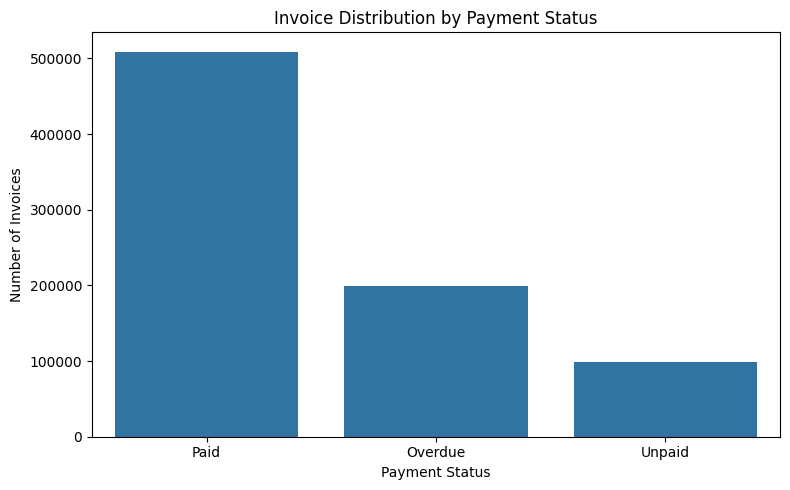

In [47]:
# Payment status distribution

df = df_billing_analysis.copy()

# Payment status distribution
status_counts = (
    df['payment_status']
    .value_counts()
    .reset_index()
)

status_counts.columns = ['payment_status', 'invoice_count']

display(status_counts)

# Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=status_counts,
    x='payment_status',
    y='invoice_count'
)

plt.title('Invoice Distribution by Payment Status')
plt.xlabel('Payment Status')
plt.ylabel('Number of Invoices')
plt.tight_layout()
plt.show()

In [48]:
# Overall KPI NPI, membuat baseline NPI yang bisa digunakan sebagai pembanding untuk analisa selanjutnya

# Define NPI
df['is_npi'] = df['payment_status'].isin(['Unpaid', 'Overdue'])

total_invoices = len(df)
npi_invoices = df['is_npi'].sum()

npi_rate = (npi_invoices / total_invoices) * 100

total_outstanding = df.loc[
    df['is_npi'],
    'total_amount'
].sum()

total_invoice_amount = df['total_amount'].sum()

print(f"Total Invoices: {total_invoices:,.0f}")
print(f"NPI Invoices: {npi_invoices:,.0f}")
print(f"NPI Rate: {npi_rate:.2f}%")
print(f"Outstanding Invoice Amount: Rp{total_outstanding:,.0f}")
print(f"Total Invoice Amount: Rp{total_invoice_amount:,.0f}")

Total Invoices: 807,427
NPI Invoices: 298,426
NPI Rate: 36.96%
Outstanding Invoice Amount: Rp246,404,842,750
Total Invoice Amount: Rp670,794,072,000


```
# Key Findings
```

Berdasarkan data, tercatat NPI rate sebesar **36.96%** dan nilainya mendukung klaim yang disebutkan pada problem statement dimana NPI rate diperkirakan sudah melebihi seperempat (>25%).

Nilai invoice yang belum dibayar mencapai sekitar Rp246,4 miliar. Ini menunjukkan potensi tekanan yang material terhadap cash flow operasional.

Catatan: angka Rp246,4 miliar merupakan nilai ```total_amount``` gabungan, bukan IPL saja.

**MONTHLY NPI TRENDS**

In [59]:
# MONTHLY NPI Trends
monthly_npi = (
    df.groupby('billing_month')
    .agg(
        total_invoices=('invoice_id', 'count'),
        npi_invoices=('is_npi', 'sum'),
        total_invoice_amount=('total_amount', 'sum'),
        outstanding_amount=(
            'total_amount',
            lambda x: x[df.loc[x.index, 'is_npi']].sum()
        )
    )
    .reset_index()
)

monthly_npi['npi_rate'] = (
    monthly_npi['npi_invoices'] /
    monthly_npi['total_invoices'] * 100
)

display(monthly_npi.head())

,billing_month,total_invoices,npi_invoices,total_invoice_amount,outstanding_amount,npi_rate
0,2022-07,19882,3983,1.638775e+10,3.128822e+09,20.033196
1,2022-08,20226,5531,1.724685e+10,4.762827e+09,27.345990
2,2022-09,20590,6488,1.702661e+10,5.461136e+09,31.510442
3,2022-10,21326,7089,1.788888e+10,6.416102e+09,33.241114
4,2022-11,22023,7471,1.816541e+10,6.237730e+09,33.923625


In [60]:
plot_data = monthly_npi.copy()

# Convert Period to Timestamp
plot_data['billing_month'] = (
    plot_data['billing_month'].dt.to_timestamp()
)

plot_data = plot_data.sort_values('billing_month')

In [61]:
# Identify peak NPI
peak_idx = plot_data['npi_rate'].idxmax()
peak = plot_data.loc[peak_idx]

latest = plot_data.iloc[-1]

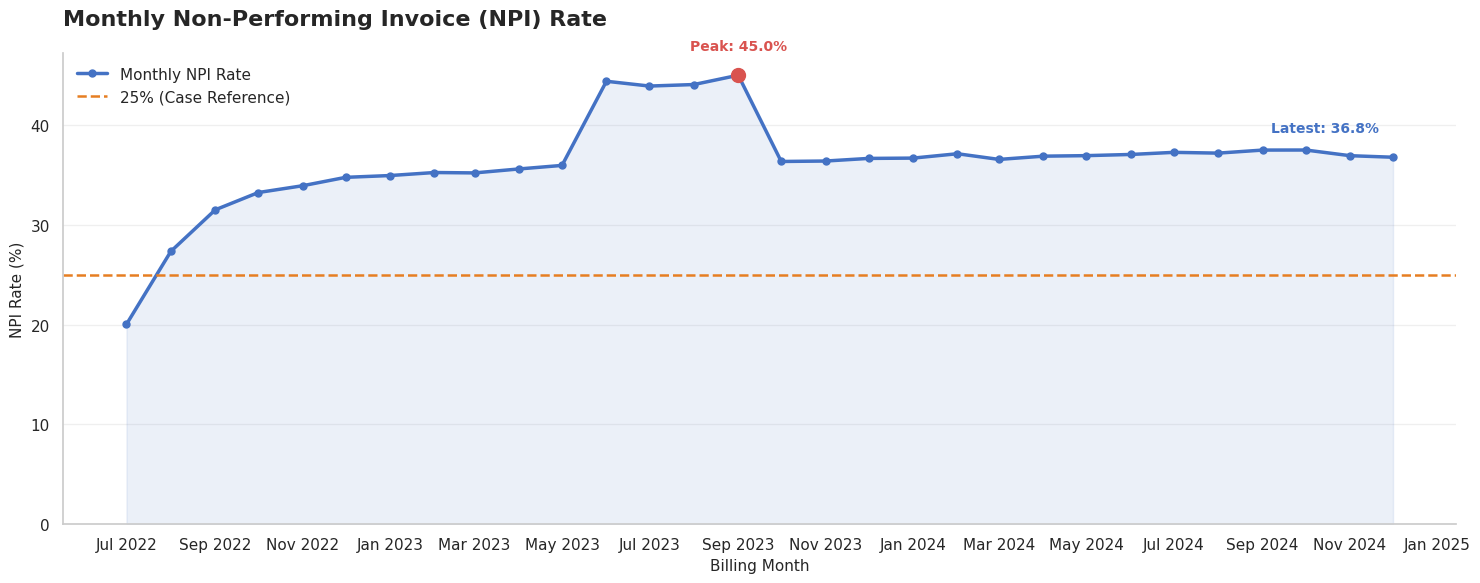

In [63]:
# Visualization
sns.set_theme(style='whitegrid')

fig, ax = plt.subplots(figsize=(15, 6))

# Main line
ax.plot(
    plot_data['billing_month'],
    plot_data['npi_rate'],
    color='#4472C4',
    linewidth=2.5,
    marker='o',
    markersize=5,
    label='Monthly NPI Rate'
)

# Shaded area
ax.fill_between(
    plot_data['billing_month'],
    plot_data['npi_rate'],
    alpha=0.10,
    color='#4472C4'
)

# Reference line
ax.axhline(
    y=25,
    color='#E67E22',
    linestyle='--',
    linewidth=1.8,
    label='25% (Case Reference)'
)

# Highlight peak
ax.scatter(
    peak['billing_month'],
    peak['npi_rate'],
    color='#D9534F',
    s=100,
    zorder=5
)

ax.annotate(
    f"Peak: {peak['npi_rate']:.1f}%",
    xy=(peak['billing_month'], peak['npi_rate']),
    xytext=(0, 18),
    textcoords='offset points',
    ha='center',
    fontsize=10,
    fontweight='bold',
    color='#D9534F'
)

# Latest value
ax.annotate(
    f"Latest: {latest['npi_rate']:.1f}%",
    xy=(latest['billing_month'], latest['npi_rate']),
    xytext=(-10, 18),
    textcoords='offset points',
    ha='right',
    fontsize=10,
    fontweight='bold',
    color='#4472C4'
)

# Formatting
ax.set_title(
    'Monthly Non-Performing Invoice (NPI) Rate',
    fontsize=16,
    fontweight='bold',
    loc='left',
    pad=20
)

ax.set_xlabel('Billing Month', fontsize=11)
ax.set_ylabel('NPI Rate (%)', fontsize=11)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.set_ylim(bottom=0)

ax.legend(
    loc='upper left',
    frameon=False
)

ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', visible=False)

sns.despine()

plt.tight_layout()
plt.show()

```
# Key Findings - Monthly NPI Rate Trend Analysis
```

NPI Rate bulanan menunjukkan tiga fase yang berbeda:

1. **July 2022 – May 2023: Gradual Increase**
- NPI rate meningkat dari sekitar **20% menjadi 36%**, menunjukkan kenaikan jumlah invoice yang masih tertunggak secara konsisten.
- NPI rate mulai melampaui tingkat referensi **25% sejak Agustus 2022**.

2. **June – September 2023: Significant Spike**
- NPI rate meningkat tajam dan mencapai puncaknya sekitar **45% pada September 2023**.
- Periode ini merupakan periode dengan tingkat NPI tertinggi selama rentang waktu billing yang diamati.

3. **October 2023 – December 2024: Decline and Stabilization**
- NPI rate turun secara signifikan menjadi sekitar **36% pada Oktober 2023**.
- Setelah penurunan tersebut, NPI rate relatif stabil pada kisaran **36–37% hingga Desember 2024**.


**Overall Observation:**

Meskipun mengalami penurunan dari puncaknya pada September 2023, NPI rate secara konsisten tetap berada di atas tingkat referensi **25%** sepanjang periode pengamatan. Hal ini menunjukkan bahwa permasalahan invoice tertunggak masih berlangsung dan belum kembali ke tingkat referensi yang diharapkan hingga Desember 2024.

**OUTSTANDING AMOUNT**

In [68]:
# Prepare data
plot_amount = monthly_npi.copy()

plot_amount['billing_month'] = (
    plot_amount['billing_month'].dt.to_timestamp()
)

plot_amount = plot_amount.sort_values('billing_month')

In [71]:
# Identify peak and latest
peak_idx = plot_amount['outstanding_amount'].idxmax()
peak = plot_amount.loc[peak_idx]

latest = plot_amount.iloc[-1]

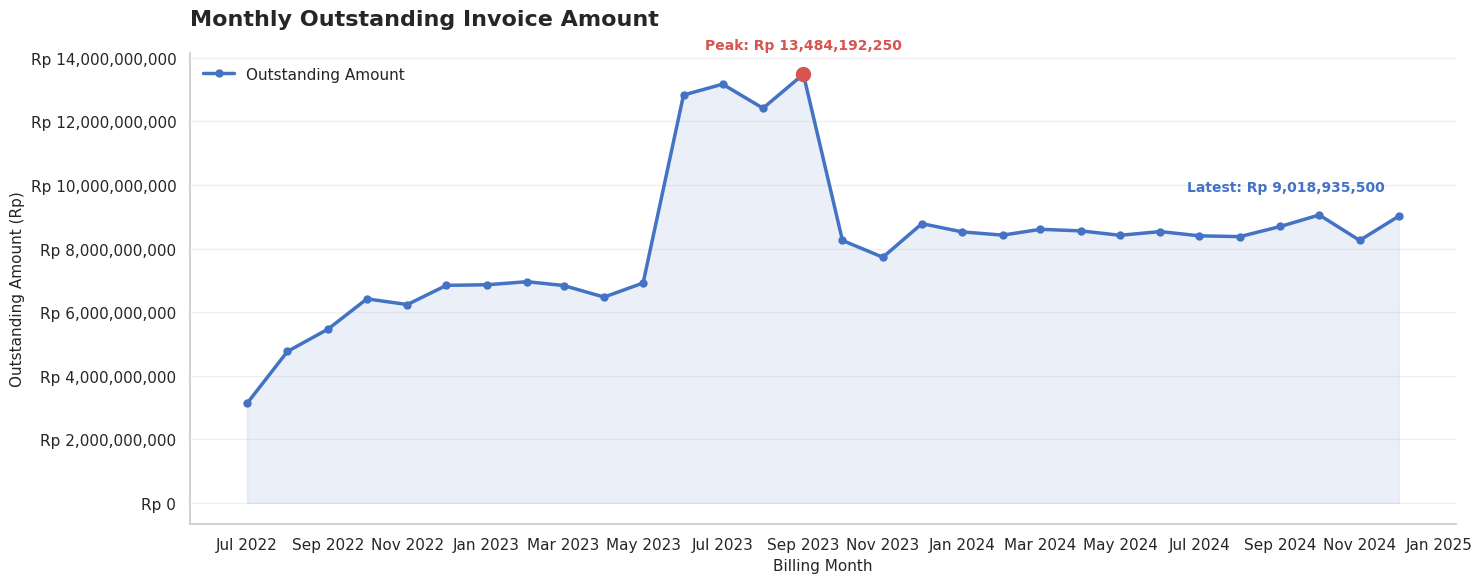

In [72]:
# Visualization
sns.set_theme(style='whitegrid')

fig, ax = plt.subplots(figsize=(15, 6))

# Main line
ax.plot(
    plot_amount['billing_month'],
    plot_amount['outstanding_amount'],
    color='#4472C4',
    linewidth=2.5,
    marker='o',
    markersize=5,
    label='Outstanding Amount'
)

# Shaded area
ax.fill_between(
    plot_amount['billing_month'],
    plot_amount['outstanding_amount'],
    alpha=0.10,
    color='#4472C4'
)

# Highlight peak
ax.scatter(
    peak['billing_month'],
    peak['outstanding_amount'],
    color='#D9534F',
    s=100,
    zorder=5
)

ax.annotate(
    f"Peak: Rp {peak['outstanding_amount']:,.0f}",
    xy=(peak['billing_month'], peak['outstanding_amount']),
    xytext=(0, 18),
    textcoords='offset points',
    ha='center',
    fontsize=10,
    fontweight='bold',
    color='#D9534F'
)

# Latest value
ax.annotate(
    f"Latest: Rp {latest['outstanding_amount']:,.0f}",
    xy=(latest['billing_month'], latest['outstanding_amount']),
    xytext=(-10, 18),
    textcoords='offset points',
    ha='right',
    fontsize=10,
    fontweight='bold',
    color='#4472C4'
)

# Format axis
ax.set_title(
    'Monthly Outstanding Invoice Amount',
    fontsize=16,
    fontweight='bold',
    loc='left',
    pad=20
)

ax.set_xlabel('Billing Month', fontsize=11)
ax.set_ylabel('Outstanding Amount (Rp)', fontsize=11)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, pos: f'Rp {x:,.0f}')
)

ax.legend(loc='upper left', frameon=False)

ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', visible=False)

sns.despine()

plt.tight_layout()
plt.show()

In [73]:
# Verify amount of outstanding invoice
monthly_outstanding_total = (
    monthly_npi['outstanding_amount'].sum()
)

print(f"Overall Outstanding: Rp{total_outstanding:,.0f}")

print(
    f"Monthly Outstanding Total: "
    f"Rp{monthly_outstanding_total:,.0f}"
)

print(
    "Validation:",
    total_outstanding == monthly_outstanding_total
)

Overall Outstanding: Rp246,404,842,750
Monthly Outstanding Total: Rp246,404,842,750
Validation: True


```
# Key Findings - Monthly Outstanding Invoice Amount
```
The monthly NPI rate shows three distinct phases:

1. **July 2022 – May 2023: Gradual Increase**
   - Outstanding amount meningkat dari sekitar Rp3,1 miliar menjadi Rp6,9 miliar, menunjukkan akumulasi tunggakan secara bertahap.

2. **June – September 2023: Significant Spike**
   - Outstanding amount melonjak tajam dan mencapai puncak sekitar Rp13,48 miliar pada September 2023.

3. **October 2023 – December 2024: Decline and Stabilization**
   - Outstanding amount turun menjadi sekitar Rp8,3 miliar pada Oktober 2023, kemudian relatif stabil di kisaran Rp8–9 miliar hingga Desember 2024.

**Overall Observation:**

Meskipun outstanding amount mengalami penurunan setelah mencapai puncaknya, nilainya tetap relatif tinggi dan belum kembali ke level sebelum lonjakan pada pertengahan 2023. Hal ini menunjukkan bahwa permasalahan tunggakan masih berlangsung dan berpotensi membebani cash flow operasional kawasan.

**Business Implication:**

Perlu dilakukan investigasi lebih lanjut terhadap faktor yang menyebabkan lonjakan outstanding pada Juni–September 2023 serta identifikasi unit dan cluster dengan kontribusi tunggakan terbesar untuk mendukung strategi collection yang lebih terarah.



# **BQ 2: Which clusters and unit characteristics contribute most to NPI?**

*   Segmen mana yang memiliki proporsi invoice bermasalah paling tinggi?
*   Segmen mana yang menyumbang nominal outstanding paling besar?

```Insight for Collection & Estate Team```


In [74]:
df = df_billing_analysis.copy()

df['is_npi'] = df['payment_status'].isin(
    ['Unpaid', 'Overdue']
)

df['outstanding_amount'] = df['total_amount'].where(
    df['is_npi'], 0
)

def analyze_npi_by_segment(data, segment):
    result = (
        data.groupby(segment, dropna=False)
        .agg(
            total_invoices=('invoice_id', 'count'),
            npi_invoices=('is_npi', 'sum'),
            outstanding_amount=('outstanding_amount', 'sum')
        )
        .reset_index()
    )

    result['npi_rate'] = (
        result['npi_invoices'] /
        result['total_invoices'] * 100
    )

    result['outstanding_contribution_pct'] = (
        result['outstanding_amount'] /
        result['outstanding_amount'].sum() * 100
    )

    return result.sort_values(
        'outstanding_amount',
        ascending=False
    )

In [75]:
# Analisa cluster characteristics

cluster_segments = [
    'township_name',
    'cluster_category',
    'facility_tier',
    'zone_type',
    'launch_phase'
]

for segment in cluster_segments:
    print(f"\nNPI ANALYSIS BY {segment.upper()}")

    result = analyze_npi_by_segment(df, segment)

    display(
        result.style.format({
            'npi_rate': '{:.2f}%',
            'outstanding_amount': 'Rp{:,.0f}',
            'outstanding_contribution_pct': '{:.2f}%'
        })
    )


NPI ANALYSIS BY TOWNSHIP_NAME


,township_name,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
3,Kota Wisata,238795,87101,"Rp75,956,881,750",36.48%,30.83%
0,BSD City,238543,89839,"Rp74,217,701,000",37.66%,30.12%
2,Grand Wisata,205466,74374,"Rp54,359,211,750",36.20%,22.06%
1,Deltamas,94419,35721,"Rp25,898,944,250",37.83%,10.51%
4,NavaPark,30204,11391,"Rp15,972,104,000",37.71%,6.48%



NPI ANALYSIS BY CLUSTER_CATEGORY


,cluster_category,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
2,Middle Residential,669371,242475,"Rp169,855,328,250",36.22%,68.93%
3,Premium Residential,96547,39913,"Rp59,560,301,500",41.34%,24.17%
0,Commercial Ruko,37894,14589,"Rp14,692,715,500",38.50%,5.96%
1,Industrial/Commercial,3615,1449,"Rp2,296,497,500",40.08%,0.93%



NPI ANALYSIS BY FACILITY_TIER


,facility_tier,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
2,Standard,438629,158728,"Rp117,249,861,500",36.19%,47.58%
0,Plus,294660,109170,"Rp83,746,148,000",37.05%,33.99%
1,Premium Resort-style,74138,30528,"Rp45,408,833,250",41.18%,18.43%



NPI ANALYSIS BY ZONE_TYPE


,zone_type,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
2,Residential Core,634435,233847,"Rp186,059,953,750",36.86%,75.51%
1,Mixed,135098,49990,"Rp45,652,173,500",37.00%,18.53%
0,Commercial Ring,37894,14589,"Rp14,692,715,500",38.50%,5.96%



NPI ANALYSIS BY LAUNCH_PHASE


,launch_phase,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
0,2018-2020 (Established),516256,177743,"Rp156,661,549,500",34.43%,63.58%
1,2021-2023 (New Phase),291171,120683,"Rp89,743,293,250",41.45%,36.42%


In [76]:
# Define visualization function
def plot_npi_analysis(data, segment):

    # 1. Outstanding Contribution
    contribution = data.sort_values(
        'outstanding_contribution_pct',
        ascending=True
    )

    plt.figure(figsize=(10, 5))

    ax = sns.barplot(
        data=contribution,
        x='outstanding_contribution_pct',
        y=segment
    )

    plt.title(f'Outstanding Contribution by {segment.replace("_", " ").title()}')
    plt.xlabel('Outstanding Contribution (%)')
    plt.ylabel(segment.replace('_', ' ').title())

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f%%', padding=3)

    plt.tight_layout()
    plt.show()

    # 2. NPI Rate
    npi_rate = data.sort_values(
        'npi_rate',
        ascending=True
    )

    plt.figure(figsize=(10, 5))

    ax = sns.barplot(
        data=npi_rate,
        x='npi_rate',
        y=segment
    )

    plt.title(f'NPI Rate by {segment.replace("_", " ").title()}')
    plt.xlabel('NPI Rate (%)')
    plt.ylabel(segment.replace('_', ' ').title())

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f%%', padding=3)

    plt.tight_layout()
    plt.show()


NPI ANALYSIS BY TOWNSHIP_NAME


,township_name,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
3,Kota Wisata,238795,87101,"Rp75,956,881,750",36.48%,30.83%
0,BSD City,238543,89839,"Rp74,217,701,000",37.66%,30.12%
2,Grand Wisata,205466,74374,"Rp54,359,211,750",36.20%,22.06%
1,Deltamas,94419,35721,"Rp25,898,944,250",37.83%,10.51%
4,NavaPark,30204,11391,"Rp15,972,104,000",37.71%,6.48%


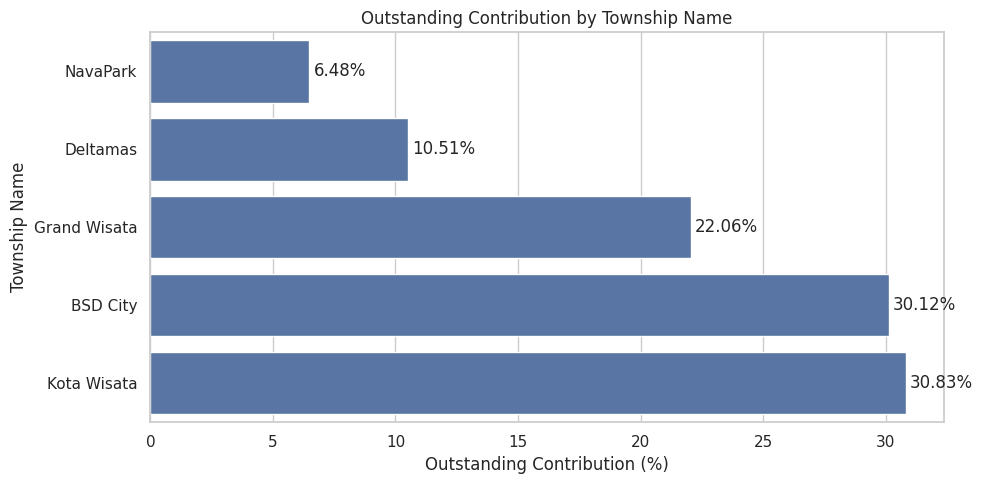

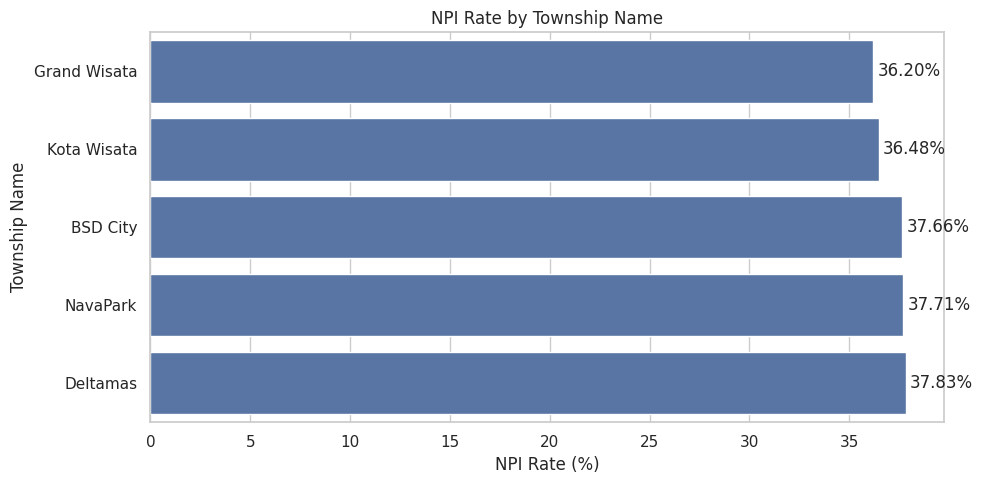


NPI ANALYSIS BY CLUSTER_CATEGORY


,cluster_category,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
2,Middle Residential,669371,242475,"Rp169,855,328,250",36.22%,68.93%
3,Premium Residential,96547,39913,"Rp59,560,301,500",41.34%,24.17%
0,Commercial Ruko,37894,14589,"Rp14,692,715,500",38.50%,5.96%
1,Industrial/Commercial,3615,1449,"Rp2,296,497,500",40.08%,0.93%


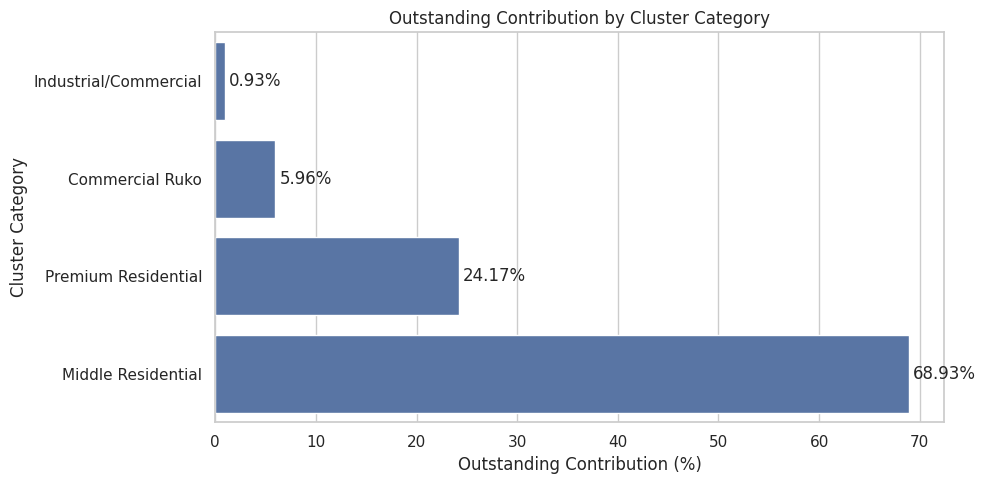

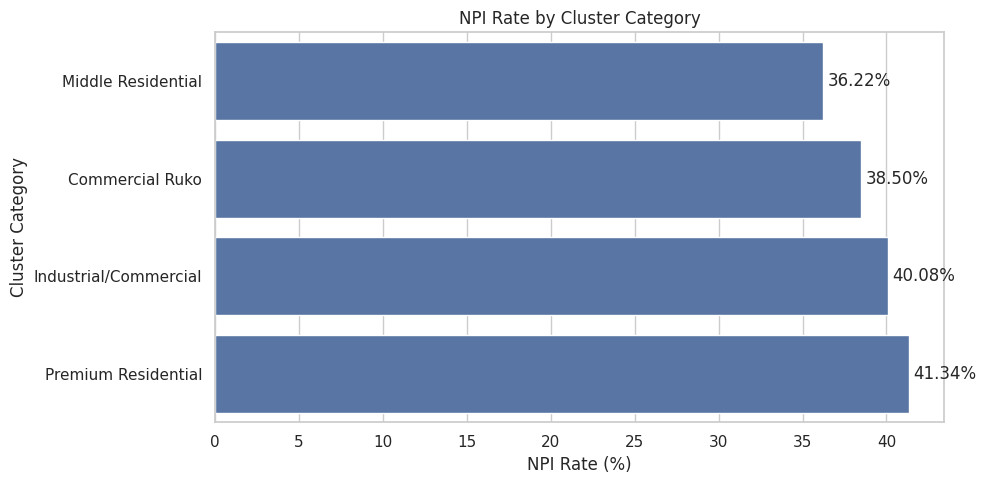


NPI ANALYSIS BY FACILITY_TIER


,facility_tier,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
2,Standard,438629,158728,"Rp117,249,861,500",36.19%,47.58%
0,Plus,294660,109170,"Rp83,746,148,000",37.05%,33.99%
1,Premium Resort-style,74138,30528,"Rp45,408,833,250",41.18%,18.43%


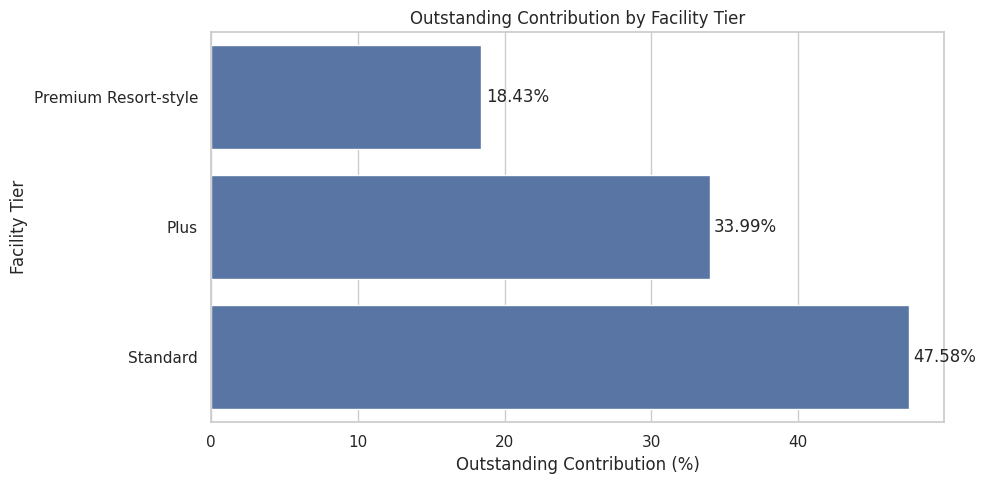

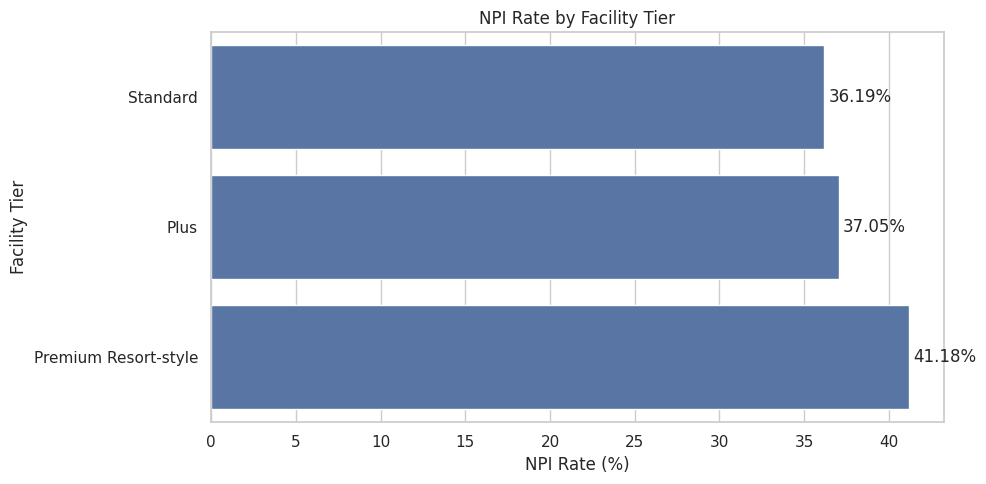


NPI ANALYSIS BY ZONE_TYPE


,zone_type,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
2,Residential Core,634435,233847,"Rp186,059,953,750",36.86%,75.51%
1,Mixed,135098,49990,"Rp45,652,173,500",37.00%,18.53%
0,Commercial Ring,37894,14589,"Rp14,692,715,500",38.50%,5.96%


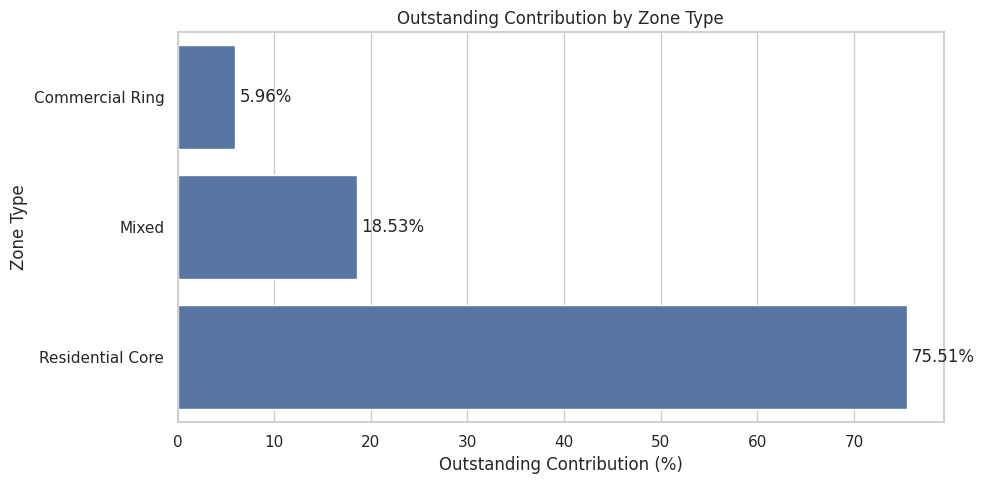

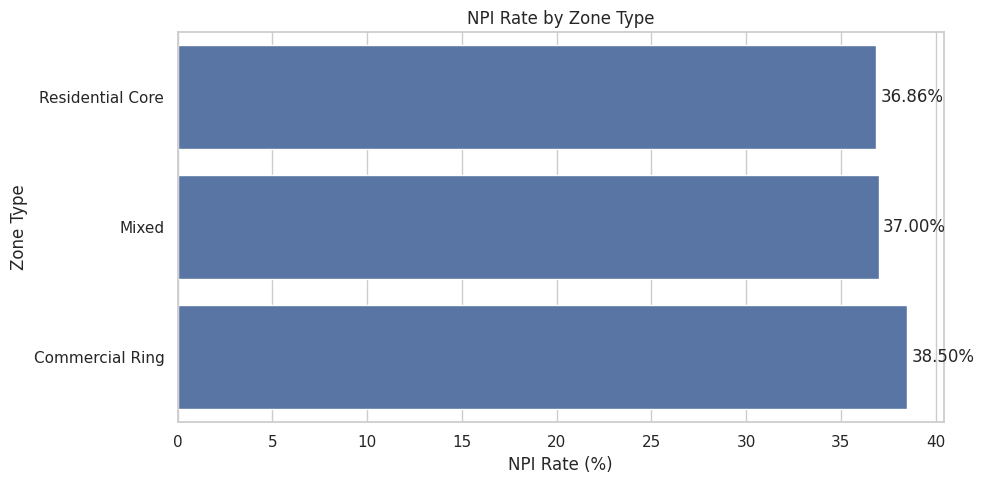


NPI ANALYSIS BY LAUNCH_PHASE


,launch_phase,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
0,2018-2020 (Established),516256,177743,"Rp156,661,549,500",34.43%,63.58%
1,2021-2023 (New Phase),291171,120683,"Rp89,743,293,250",41.45%,36.42%


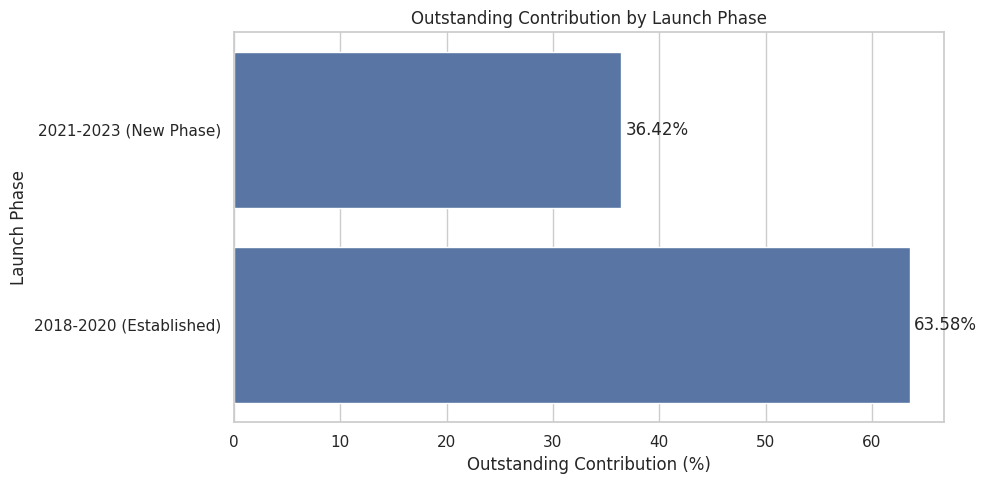

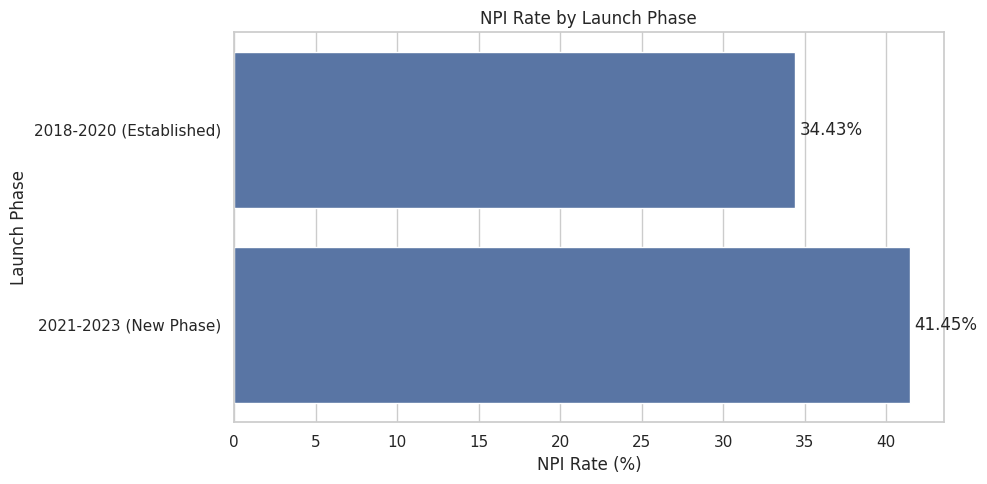

In [78]:
cluster_segments = [
    'township_name',
    'cluster_category',
    'facility_tier',
    'zone_type',
    'launch_phase'
]

for segment in cluster_segments:

    print(f"\nNPI ANALYSIS BY {segment.upper()}")

    result = analyze_npi_by_segment(df, segment)

    display(
        result.style.format({
            'npi_rate': '{:.2f}%',
            'outstanding_amount': 'Rp{:,.0f}',
            'outstanding_contribution_pct': '{:.2f}%'
        })
    )

    # Visualisasi
    plot_npi_analysis(result, segment)

```
# Key Findings - NPI Analysis by Unit & Cluster Characteristics
```

## 1. Township
- **Highest Outstanding Contribution:** Kota Wisata (30.83% atau Rp75.96 miliar), diikuti oleh BSD City (30.12% atau Rp74.22 miliar).
- **Highest NPI Rate:** Deltamas (37.83%), meskipun perbedaan antar-township relatif kecil, dengan NPI rate berkisar antara 36.20% hingga 37.83%.

**Key Insight:** Eksposur outstanding terkonsentrasi di Kota Wisata dan BSD City, sementara NPI rate relatif konsisten di seluruh township.

---

## 2. Cluster Category
- **Highest Outstanding Contribution:** Middle Residential (68.93% atau Rp169.86 miliar).
- **Lowest Outstanding Contribution:** Industrial/Commercial (0.93% atau Rp2.30 miliar).
- **Highest NPI Rate:** Premium Residential (41.34%), diikuti oleh Industrial/Commercial (40.08%).
- Middle Residential memiliki NPI rate terendah sebesar 36.22%.

**Key Insight:** Middle Residential mendominasi eksposur outstanding karena volume invoice yang besar, sedangkan Premium Residential dan Industrial/Commercial menunjukkan NPI rate yang lebih tinggi.

---

## 3. Facility Tier
- **Highest Outstanding Contribution:** Standard (47.58% atau Rp117.25 miliar).
- **Lowest Outstanding Contribution:** Premium Resort-style (18.43% atau Rp45.41 miliar).
- **Highest NPI Rate:** Premium Resort-style (41.18%).
- **Lowest NPI Rate:** Standard (36.19%).

**Key Insight:** Standard Tier berkontribusi terhadap jumlah outstanding terbesar, sedangkan Premium Resort-style memiliki proporsi invoice NPI yang lebih tinggi.

---

## 4. Zone Type
- **Highest Outstanding Contribution:** Residential Core (75.51% atau Rp186.06 miliar).
- **Lowest Outstanding Contribution:** Commercial Ring (5.96% atau Rp14.69 miliar).
- **Highest NPI Rate:** Commercial Ring (38.50%), diikuti oleh Mixed (37.00%) dan Residential Core (36.86%).

**Key Insight:** Residential Core mencakup sebagian besar eksposur outstanding, sedangkan Commercial Ring memiliki NPI rate tertinggi di antara seluruh tipe zona.

---

## 5. Launch Phase
- **Highest Outstanding Contribution:** Established Phase (63.58% atau Rp156.66 miliar).
- **Highest NPI Rate:** New Phase (41.45%), dibandingkan dengan 34.43% pada Established Phase.

**Key Insight:** Established Phase berkontribusi lebih besar terhadap eksposur outstanding karena volume invoice yang lebih tinggi, sedangkan New Phase memiliki proporsi invoice NPI yang lebih besar.

---

# Overall Key Findings

### 1. Eksposur Outstanding Terkonsentrasi pada Segmen dengan Volume Invoice Tinggi
Kota Wisata, Middle Residential, Standard Tier, Residential Core, dan Established Phase merupakan kontributor outstanding terbesar dalam masing-masing dimensi.

### 2. Kontribusi Outstanding Tertinggi Tidak Selalu Berarti NPI Rate Tertinggi
Premium Residential, Premium Resort-style, Commercial Ring, dan New Phase memiliki NPI rate yang lebih tinggi dibandingkan segmen dengan kontribusi outstanding terbesar dalam masing-masing dimensinya.

### 3. Prioritas Penagihan Membutuhkan Dua Perspektif
- **Prioritas berdasarkan outstanding:** Berfokus pada segmen yang berkontribusi terhadap jumlah outstanding terbesar untuk mengurangi eksposur finansial.
- **Prioritas berdasarkan NPI rate:** Menginvestigasi segmen dengan NPI rate lebih tinggi untuk memahami pola risiko pembayaran yang berpotensi terjadi.

---

## Business Implications

| Fokus Penagihan | Segmen Prioritas | Pendekatan yang Direkomendasikan |
|---|---|---|
| Pengurangan Outstanding | Middle Residential, Standard, Residential Core, Established Phase | Memprioritaskan penagihan berdasarkan jumlah outstanding |
| NPI Rate Lebih Tinggi | Premium Residential, Premium Resort-style, Commercial Ring, New Phase | Menginvestigasi pola pembayaran dan faktor risiko yang berpotensi memengaruhi |

**Note:** Temuan ini menunjukkan adanya keterkaitan antara karakteristik segmen dan pola NPI. Namun, temuan tersebut tidak membuktikan adanya hubungan sebab-akibat.

# **BQ 3: How significant is the contribution of vacant units to total NPI?**


NPI ANALYSIS BY UNIT_TYPE


,unit_type,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
1,Rumah Tapak,769533,283837,"Rp231,712,127,250",36.88%,94.04%
0,Ruko,37894,14589,"Rp14,692,715,500",38.50%,5.96%


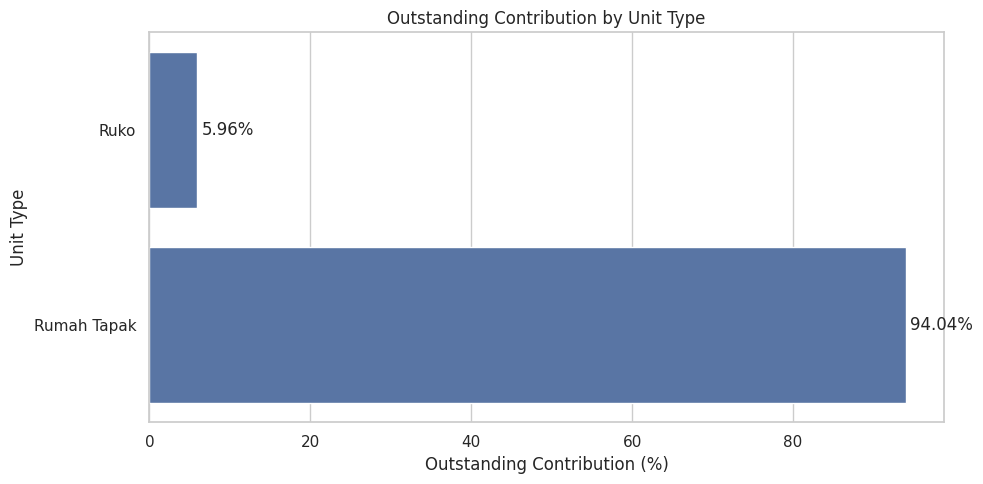

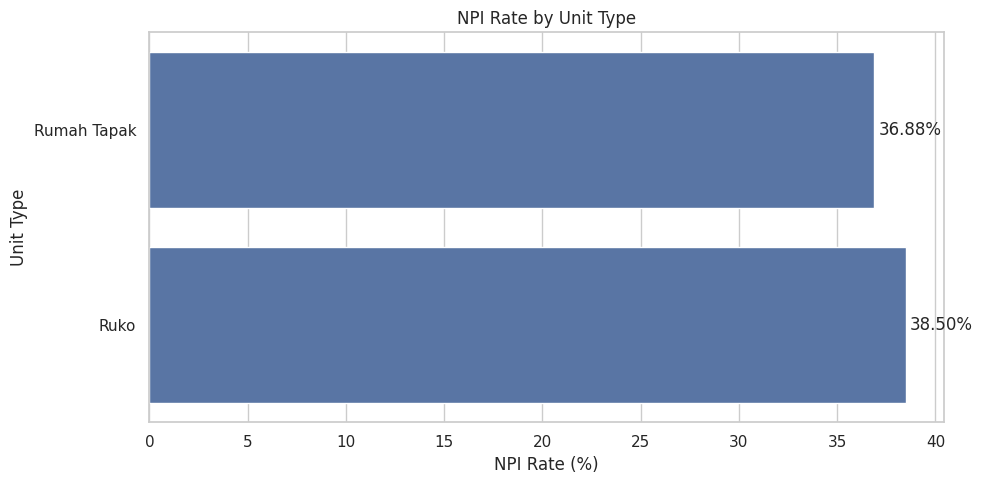


NPI ANALYSIS BY IS_VACANT


,is_vacant,total_invoices,npi_invoices,outstanding_amount,npi_rate,outstanding_contribution_pct
0,False,612200,182405,"Rp154,465,338,000",29.80%,62.69%
1,True,195227,116021,"Rp91,939,504,750",59.43%,37.31%


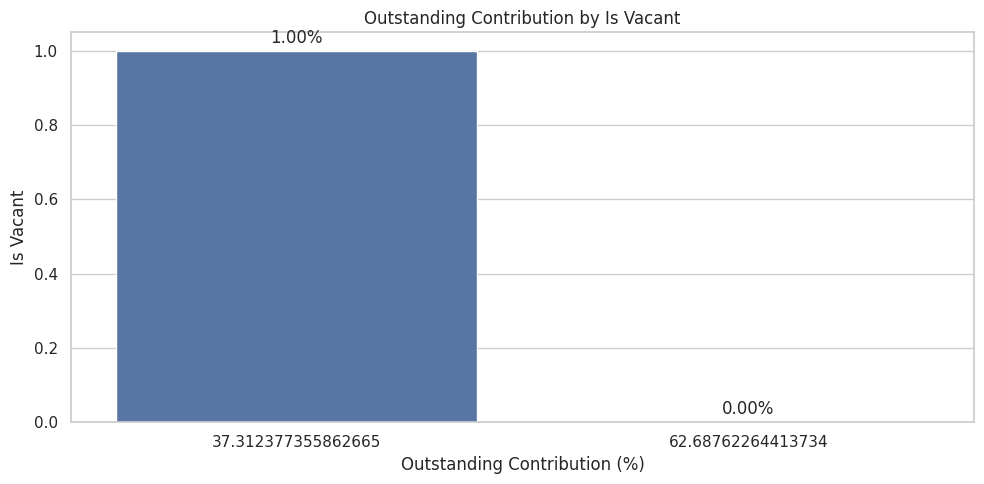

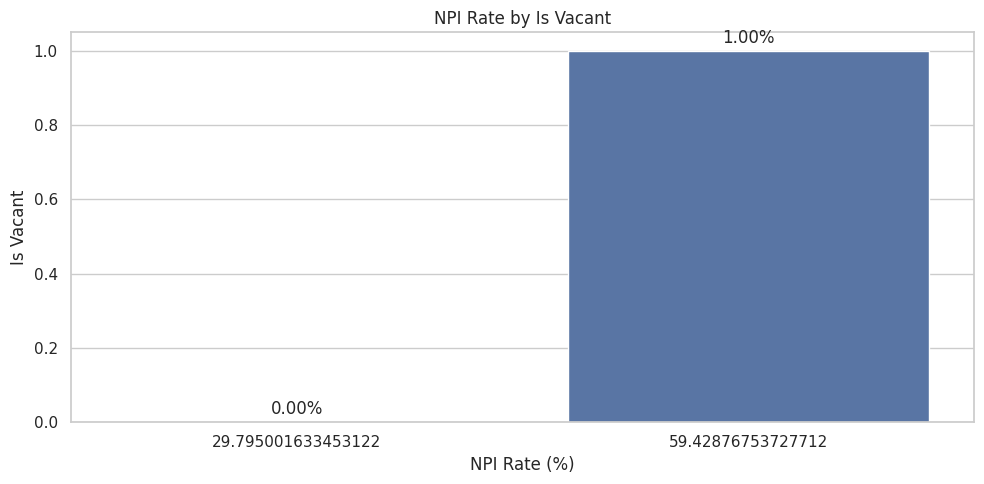

In [93]:
# Analisa vacant units
unit_segments = [
    'unit_type',
    'is_vacant',
]

for segment in unit_segments:
    print(f"\nNPI ANALYSIS BY {segment.upper()}")

    result = analyze_npi_by_segment(df, segment)

    display(
        result.style.format({
            'npi_rate': '{:.2f}%',
            'outstanding_amount': 'Rp{:,.0f}',
            'outstanding_contribution_pct': '{:.2f}%'
        })
    )


    # Visualisasi
    plot_npi_analysis(result, segment)

```
# Key Findings: How Significant Is the Contribution of Vacant Units to Total NPI?
```
## 1. Vacancy Status
- **Highest NPI Rate:** Unit Vacant (59.43%), hampir dua kali lipat dibandingkan unit Occupied (29.80%).
- Unit Vacant berkontribusi sebesar 37.31% terhadap total outstanding invoice, setara dengan sekitar Rp91.94 miliar.
- Meskipun memiliki jumlah invoice lebih sedikit dibandingkan unit Occupied, unit Vacant menunjukkan NPI rate yang jauh lebih tinggi.

**Key Insight:** Unit Vacant menjadi salah satu perhatian utama dalam proses penagihan, dengan hampir 60% invoice-nya diklasifikasikan sebagai NPI. Kontribusinya sebesar Rp91.94 miliar terhadap total outstanding invoice menunjukkan pentingnya memprioritaskan unit Vacant dalam strategi penagihan.

---

## 2. Unit Type
- **Highest Outstanding Contribution:** Rumah Tapak, yang mencakup 94.04% dari total outstanding.
- **Highest NPI Rate:** Ruko (38.50%), sedikit lebih tinggi dibandingkan Rumah Tapak (36.88%).

**Key Insight:** Rumah Tapak mendominasi eksposur outstanding karena memiliki volume invoice yang jauh lebih besar. Namun, Ruko memiliki NPI rate yang sedikit lebih tinggi, menunjukkan proporsi invoice bermasalah yang juga sedikit lebih besar.

---

# Overall Key Findings

### 1. Unit Vacant Memiliki NPI Rate yang Jauh Lebih Tinggi
Unit Vacant memiliki NPI rate sebesar 59.43%, hampir dua kali lipat dibandingkan unit Occupied (29.80%), serta berkontribusi sebesar Rp91.94 miliar atau 37.31% dari total outstanding invoice.

### 2. Eksposur Outstanding Terkonsentrasi pada Rumah Tapak
Rumah Tapak berkontribusi sebesar 94.04% terhadap total outstanding invoice, sedangkan Ruko memiliki NPI rate yang sedikit lebih tinggi (38.50%).

---

## Business Implications

| Area Fokus | Segmen Prioritas | Pendekatan yang Direkomendasikan |
|---|---|---|
| Penagihan berdasarkan status hunian | Unit Vacant | Memprioritaskan pemantauan outstanding dan tindak lanjut penagihan |
| Penagihan berdasarkan tipe unit | Rumah Tapak | Berfokus pada segmen dengan eksposur outstanding terbesar |

**Data Limitation:** Status hunian mencerminkan kondisi unit saat ini dan tidak menunjukkan apakah suatu unit berada dalam kondisi kosong selama periode billing historis. Temuan ini menunjukkan adanya keterkaitan dan tidak boleh diinterpretasikan sebagai hubungan sebab-akibat.

# **BQ 4: Are there unusual water usage patterns or billing records among vacant units?**

**Compare water usage Vacant vs. Occupied**

In [105]:
# Filter valid water usage records (exclude negative values)
valid_water = df_billing_analysis[
    df_billing_analysis['water_usage_m3'] >= 0
].copy()

# Compare water usage by unit occupancy
water_usage_comparison = (
    valid_water
    .groupby('is_vacant')
    .agg(
        total_invoices=('invoice_id', 'count'),
        avg_water_usage=('water_usage_m3', 'mean'),
        median_water_usage=('water_usage_m3', 'median'),
        max_water_usage=('water_usage_m3', 'max')
    )
    .reset_index()
)

water_usage_comparison['unit_status'] = (
    water_usage_comparison['is_vacant']
    .map({True: 'Vacant', False: 'Occupied'})
)

display(
    water_usage_comparison[
        ['unit_status', 'total_invoices', 'avg_water_usage',
         'median_water_usage', 'max_water_usage']
    ].style.format({
        'avg_water_usage': '{:.2f} m³',
        'median_water_usage': '{:.2f} m³',
        'max_water_usage': '{:,.2f} m³'
    })
)

,unit_status,total_invoices,avg_water_usage,median_water_usage,max_water_usage
0,Occupied,609323,43.68 m³,17.70 m³,"9,996.00 m³"
1,Vacant,194280,26.00 m³,1.50 m³,"9,994.00 m³"


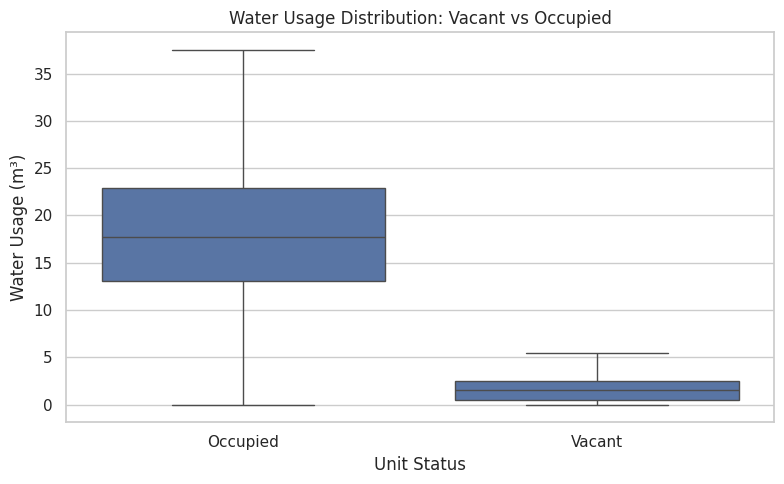

In [106]:
# Visualization
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=valid_water,
    x='is_vacant',
    y='water_usage_m3',
    showfliers=False # to hide outliers
)

plt.xticks([0, 1], ['Occupied', 'Vacant'])
plt.title('Water Usage Distribution: Vacant vs Occupied')
plt.xlabel('Unit Status')
plt.ylabel('Water Usage (m³)')

plt.tight_layout()
plt.show()

**Identify unusual water usage records**

In [107]:
# Identify negative water usage
negative_water = df_billing_analysis[
    df_billing_analysis['water_usage_m3'] < 0
]

# Identify high water usage
high_water = valid_water[
    valid_water['water_usage_m3'] >= 35
]

# Summarize unusual records
water_anomaly_summary = pd.DataFrame({
    'Anomaly Type': [
        'Negative Water Usage',
        'High Water Usage (>=35 m³)'
    ],
    'Invoice Count': [
        len(negative_water),
        len(high_water)
    ],
    'Percentage (%)': [
        len(negative_water) / len(df_billing_analysis) * 100,
        len(high_water) / len(valid_water) * 100
    ]
})

display(
    water_anomaly_summary.style.format({
        'Percentage (%)': '{:.2f}%'
    })
)

,Anomaly Type,Invoice Count,Percentage (%)
0,Negative Water Usage,3824,0.47%
1,High Water Usage (>=35 m³),35610,4.43%


**Input Method Check for Each Anomaly**

In [108]:
# Negative water usage by input method
negative_method = (
    negative_water['water_meter_input_method']
    .value_counts(dropna=False)
    .reset_index()
)

negative_method.columns = [
    'input_method',
    'invoice_count'
]

display(negative_method)

,input_method,invoice_count
0,Manual,3824


In [109]:
# High water usage by input method
high_method = (
    high_water
    .groupby('water_meter_input_method')
    .agg(
        invoice_count=('invoice_id', 'count'),
        avg_water_usage=('water_usage_m3', 'mean'),
        max_water_usage=('water_usage_m3', 'max')
    )
    .reset_index()
)

display(
    high_method.style.format({
        'avg_water_usage': '{:.2f} m³',
        'max_water_usage': '{:,.2f} m³'
    })
)

,water_meter_input_method,invoice_count,avg_water_usage,max_water_usage
0,Manual,27683,758.72 m³,"9,996.00 m³"
1,Otomatis,7927,43.34 m³,97.80 m³


**Compare high water usage rate by input method**

*Compare invoice_count, high_water, and proportion to every total invoice's input method*

In [110]:
# Total invoices by input method
total_by_method = (
    valid_water
    .groupby('water_meter_input_method')
    .agg(
        total_invoices=('invoice_id', 'count')
    )
)

# High usage invoices by input method
high_by_method = (
    high_water
    .groupby('water_meter_input_method')
    .agg(
        high_usage_invoices=('invoice_id', 'count')
    )
)

# Combine results
water_method_comparison = (
    total_by_method
    .join(high_by_method)
    .fillna(0)
    .reset_index()
)

# Calculate high usage rate
water_method_comparison['high_usage_pct'] = (
    water_method_comparison['high_usage_invoices']
    / water_method_comparison['total_invoices']
    * 100
)

display(
    water_method_comparison.style.format({
        'high_usage_pct': '{:.2f}%',
        'total_invoices': '{:,.0f}',
        'high_usage_invoices': '{:,.0f}'
    })
)

,water_meter_input_method,total_invoices,high_usage_invoices,high_usage_pct
0,Manual,"629,042","27,683",4.40%
1,Otomatis,"174,561","7,927",4.54%


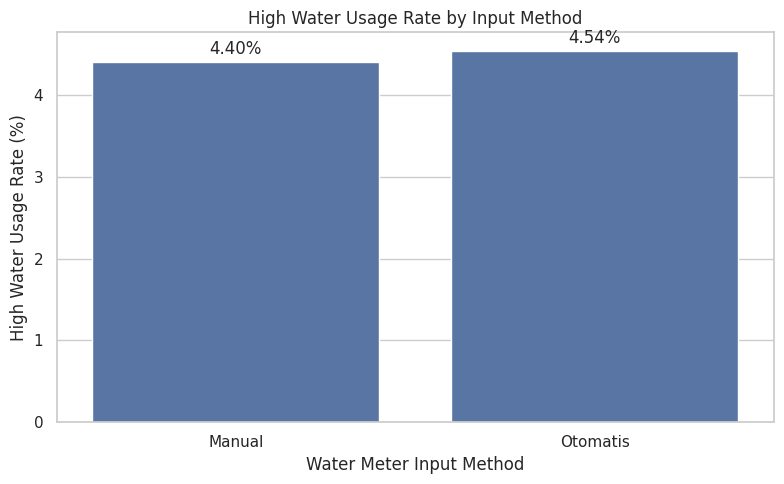

In [111]:
# Visualization
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=water_method_comparison,
    x='water_meter_input_method',
    y='high_usage_pct'
)

plt.title('High Water Usage Rate by Input Method')
plt.xlabel('Water Meter Input Method')
plt.ylabel('High Water Usage Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()

```
# Key Findings - BQ 4
```

## 1. Water Usage Comparison: Vacant vs. Occupied

| Metric | Occupied | Vacant |
|---|---|---|
| Average Usage | 43.68 m³ | P26.00 m³ |
| Median usage | 17.7 m³ | 1.5 m³ |

**Key Insights:** Vacant units memiliki median penggunaan air yang jauh lebih rendah dibandingkan occupied units. Ini sesuai dengan ekspektasi bahwa unit yang tidak dihuni cenderung memiliki aktivitas penggunaan air lebih rendah.

## 2. Unusual Water Usage
- 3,824 invoice memiliki water usage negatif dan seluruhnya menggunakan metode input manual.
- Terdapat pencatatan penggunaan air ekstrem hingga hampir 10,000 m³.

**Key Insights:** Terdapat indikasi anomali pencatatan water usage, terutama pada nilai negatif dan nilai ekstrem. Data tersebut perlu divalidasi lebih lanjut oleh tim terkait.

## 3. Compare unusual water usage by input method

| Input Method | High Usage Rate |
|---|---|
| Manual | 4.40% |
| Otomatis | 4.54% |

**Key Insights:** Proporsi invoice dengan penggunaan air ≥35 m³ relatif serupa antara metode Manual dan Otomatis. Namun, nilai penggunaan ekstrem ditemukan pada metode Manual, sehingga pencatatan manual tetap perlu mendapat perhatian dalam proses validasi.

# **BQ 5: Which collection actions types are associated with the highest successful payment responses?**

**COLLECTION ACTION DISTRIBUTION**

*Tujuan: Memahami jumlah setiap kategori sebelum membandingkan efektivitas nya.*

In [112]:
# Distribution of collection action types
display(
    df_collection_analysis['action_type']
    .value_counts()
    .rename('total_actions')
)

# Distribution of response status
display(
    df_collection_analysis['response_status']
    .value_counts()
    .rename('total_responses')
)

,total_actions
action_type,
Telepon,82806
SMS,35747
Surat,8219


,total_responses
response_status,
Tidak Respon,76715
Janji Bayar,33009
Sengketa,11468
Lunas Setelah Kontak,5580


**ANALYZE SUCCESSFUL PAYMENT RESPONSE BY ACTION TYPE**

```Successful Payment Response:``` **Lunas Setelah Kontak**

In [113]:
# Define successful payment response
df_collection_analysis['is_successful'] = (
    df_collection_analysis['response_status']
    == 'Lunas Setelah Kontak'
)

# Analyze collection effectiveness by action type
collection_effectiveness = (
    df_collection_analysis
    .groupby('action_type')
    .agg(
        total_actions=('action_id', 'count'),
        successful_responses=('is_successful', 'sum')
    )
    .reset_index()
)

# Calculate successful response rate
collection_effectiveness['success_rate'] = (
    collection_effectiveness['successful_responses']
    / collection_effectiveness['total_actions']
    * 100
)

# Sort by success rate
collection_effectiveness = (
    collection_effectiveness
    .sort_values('success_rate', ascending=False)
)

display(
    collection_effectiveness.style.format({
        'success_rate': '{:.2f}%',
        'total_actions': '{:,.0f}',
        'successful_responses': '{:,.0f}'
    })
)

,action_type,total_actions,successful_responses,success_rate
1,Surat,"8,219",429,5.22%
0,SMS,"35,747","1,790",5.01%
2,Telepon,"82,806","3,361",4.06%


```
# Key Insight
```
Surat memiliki successful payment response rate tertinggi, diikuti SMS dan Telepon. Namun, selisih Surat dan SMS hanya 0.21 percentage points, dan jumlah tindakan Surat jauh lebih sedikit.


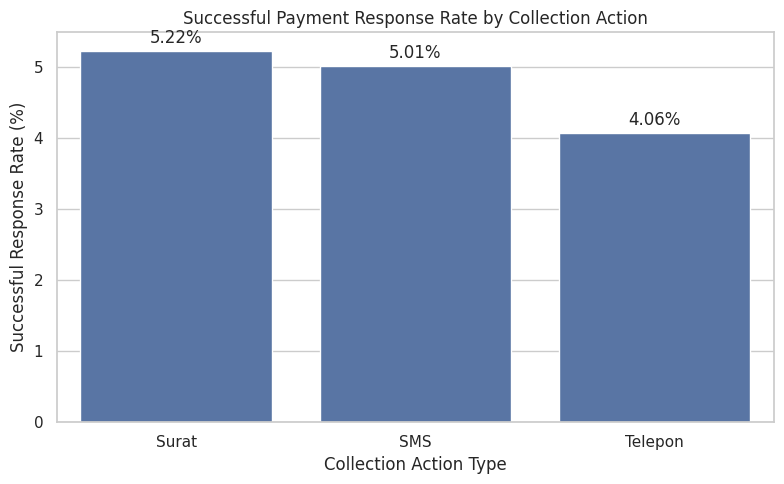

In [114]:
# Visualization
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=collection_effectiveness,
    x='action_type',
    y='success_rate'
)

plt.title('Successful Payment Response Rate by Collection Action')
plt.xlabel('Collection Action Type')
plt.ylabel('Successful Response Rate (%)')

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3)

plt.tight_layout()
plt.show()

```
# Key Findings - Collection Effectiveness
```
1. **Surat** mencatat tingkat keberhasilan respons pembayaran tertinggi sebesar **5.22%**, meskipun memiliki jumlah aktivitas penagihan paling sedikit (8,219).

2. **SMS** mencapai tingkat keberhasilan yang hampir sama, yaitu **5.01%**, dengan selisih hanya 0.21 poin persentase dibandingkan Surat.

3. **Telepon** merupakan metode penagihan yang paling sering digunakan, mencakup 65.32% dari seluruh aktivitas penagihan. Namun, metode ini mencatat tingkat keberhasilan terendah, yaitu **4.06%**.

4. Secara keseluruhan, tingkat keberhasilan respons pembayaran relatif rendah pada seluruh metode penagihan, menunjukkan adanya peluang untuk meningkatkan efektivitas proses penagihan.

**Business Implications:**

- Mengevaluasi potensi pendekatan penagihan melalui Surat dan SMS.
- Meninjau strategi penagihan melalui Telepon yang saat ini diterapkan untuk mengidentifikasi peluang perbaikan.
- Mempertimbangkan pendekatan penagihan yang lebih terarah berdasarkan pola respons pelanggan.

# **BQ 6: How Does Reminder Frequency Relate to Invoice Payment Status?**

```reminder_sent_count``` sebagai variabel frekuensi reminder.

```payment_status``` sebagai variabel status pembayaran.

```df_billing_analysis``` sebagai dataset utama.

In [115]:
# Reminder frequency distribution
reminder_distribution = (
    df_billing_analysis['reminder_sent_count']
    .value_counts(dropna=False)
    .sort_index()
    .reset_index()
)

reminder_distribution.columns = [
    'reminder_sent_count',
    'total_invoices'
]

display(reminder_distribution)

,reminder_sent_count,total_invoices
0,0,198171
1,1,221986
2,2,151356
3,3,94999
4,4,61886
5,5,38366
6,6,40663


**Analyze reminder frequency by payment status**

In [116]:
reminder_by_status = (
    df_billing_analysis
    .groupby('payment_status')
    .agg(
        total_invoices=('invoice_id', 'count'),
        avg_reminders=('reminder_sent_count', 'mean'),
        median_reminders=('reminder_sent_count', 'median'),
        min_reminders=('reminder_sent_count', 'min'),
        max_reminders=('reminder_sent_count', 'max')
    )
    .reset_index()
)

display(
    reminder_by_status.style.format({
        'avg_reminders': '{:.2f}',
        'median_reminders': '{:.0f}'
    })
)

,payment_status,total_invoices,avg_reminders,median_reminders,min_reminders,max_reminders
0,Overdue,199021,3.04,3,0,6
1,Paid,509001,1.00,1,0,6
2,Unpaid,99405,3.81,4,0,6


**Analyze payment status distribution by reminder freq**

In [117]:
# Cross-tabulation: Reminder Frequency vs Payment Status
reminder_status = pd.crosstab(
    df_billing_analysis['reminder_sent_count'],
    df_billing_analysis['payment_status']
)

display(reminder_status)

payment_status,Overdue,Paid,Unpaid
reminder_sent_count,,,
0,8972,187423,1776
1,27639,187072,7275
2,43159,93794,14403
3,44461,31027,19511
4,34481,7868,19537
5,21386,1505,15475
6,18923,312,21428


In [118]:
reminder_status_pct = pd.crosstab(
    df_billing_analysis['reminder_sent_count'],
    df_billing_analysis['payment_status'],
    normalize='index'
) * 100

display(
    reminder_status_pct.style.format('{:.2f}%')
)

payment_status,Overdue,Paid,Unpaid
reminder_sent_count,,,
0,4.53%,94.58%,0.90%
1,12.45%,84.27%,3.28%
2,28.51%,61.97%,9.52%
3,46.80%,32.66%,20.54%
4,55.72%,12.71%,31.57%
5,55.74%,3.92%,40.34%
6,46.54%,0.77%,52.70%


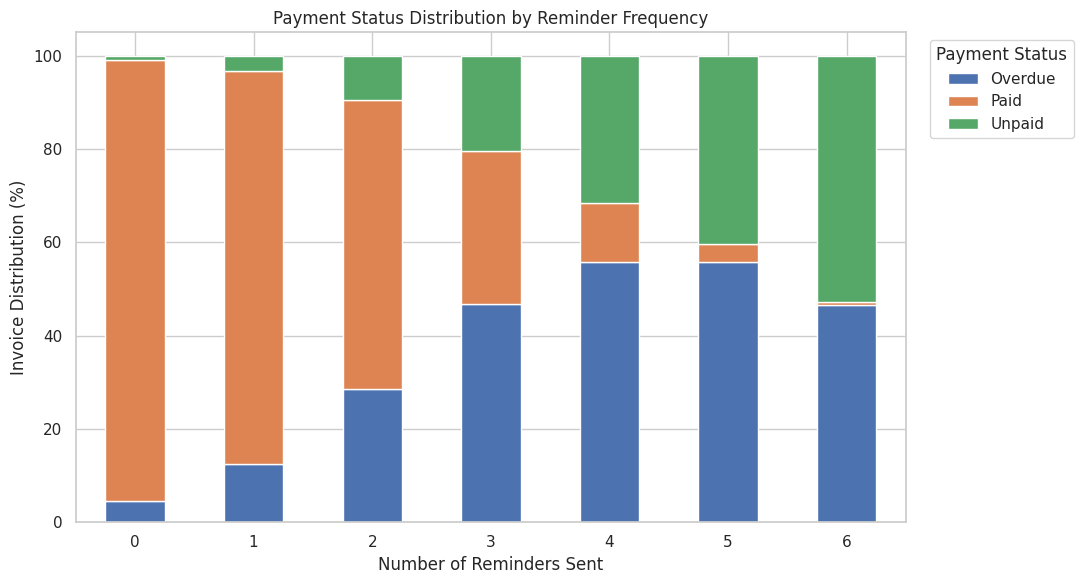

In [119]:
# Visualize payment status distribution
reminder_status_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 6)
)

plt.title('Payment Status Distribution by Reminder Frequency')
plt.xlabel('Number of Reminders Sent')
plt.ylabel('Invoice Distribution (%)')
plt.legend(title='Payment Status', bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

```
# Key Findings - How Does Reminder Frequency Relate to Invoice Payment Status?
```

1. **Frekuensi pengiriman reminder yang lebih tinggi berkaitan dengan proporsi invoice Paid yang lebih rendah.** Proporsi invoice Paid menurun dari 94.58% pada invoice yang tidak menerima reminder menjadi hanya 0.77% pada invoice yang menerima enam reminder.

2. **Invoice yang menerima lebih banyak reminder menunjukkan proporsi status Unpaid yang lebih tinggi.** Proporsi invoice Unpaid meningkat dari 0.90% pada invoice yang tidak menerima reminder menjadi 52.70% pada invoice yang menerima enam reminder.

3. **Invoice Unpaid memiliki rata-rata frekuensi reminder tertinggi.** Invoice Unpaid menerima rata-rata 3.81 reminder, diikuti oleh invoice Overdue dengan rata-rata 3.04 reminder, sedangkan invoice Paid menerima rata-rata 1.00 reminder.

**Overall Finding:**

Frekuensi pengiriman reminder yang lebih tinggi berkaitan dengan proporsi status pembayaran bermasalah yang lebih besar. Hal ini menunjukkan bahwa invoice yang membutuhkan reminder berulang mungkin memerlukan perhatian tambahan dalam proses penagihan dan strategi tindak lanjut.

**Limitation:**

Analisis ini mengidentifikasi keterkaitan, bukan hubungan sebab-akibat. Karena timestamp pengiriman reminder tidak tersedia, analisis ini tidak dapat memastikan apakah reminder dikirim sebelum atau setelah invoice berstatus Overdue atau Unpaid.

Kesimpulan BQ6: Repeated reminders are associated with invoices that have greater payment difficulties. Oleh karena itu, collection team perlu memberikan perhatian lebih pada invoice yang tetap belum dibayar meskipun sudah menerima beberapa reminders.

# **BQ 7: What payment methods are most frequently used and what naming inconsistencies need standardization?**

**PAYMENT METHOD DISTRIBUTION**

In [120]:
# Payment method distribution
payment_method_distribution = (
    df_billing_analysis['payment_method']
    .value_counts(dropna=False)
    .reset_index()
)

payment_method_distribution.columns = [
    'payment_method',
    'total_transactions'
]

# Calculate percentage among non-missing payment methods
total_paid_transactions = (
    df_billing_analysis['payment_method'].notna().sum()
)

payment_method_distribution['percentage'] = (
    payment_method_distribution['total_transactions']
    / total_paid_transactions
    * 100
)

display(
    payment_method_distribution.style.format({
        'total_transactions': '{:,.0f}',
        'percentage': '{:.2f}%'
    })
)

,payment_method,total_transactions,percentage
0,nan,"298,426",58.63%
1,BCA Virtual Account,"81,079",15.93%
2,VA BCA,"76,040",14.94%
3,bca va,"71,358",14.02%
4,Cash,"66,264",13.02%
5,KAS,"61,174",12.02%
6,Credit Card,"40,820",8.02%
7,Tokopedia,"40,698",8.00%
8,toped,"35,832",7.04%
9,cc,"35,736",7.02%


**CHECK NAMING INCOSISTENCIES**

In [121]:
# Identify unique payment method values
payment_method_variants = (
    df_billing_analysis['payment_method']
    .value_counts(dropna=False)
    .rename_axis('payment_method')
    .reset_index(name='total_transactions')
)

display(payment_method_variants)

,payment_method,total_transactions
0,NaN,298426
1,BCA Virtual Account,81079
2,VA BCA,76040
3,bca va,71358
4,Cash,66264
5,KAS,61174
6,Credit Card,40820
7,Tokopedia,40698
8,toped,35832
9,cc,35736


**NORMALIZING NAMING**

In [123]:
# Define payment method mapping
payment_method_mapping = {
    'bca virtual account': 'BCA Virtual Account',
    'va bca': 'BCA Virtual Account',
    'bca va': 'BCA Virtual Account',

    'cash': 'Cash',
    'kas': 'Cash',

    'credit card': 'Credit Card',
    'cc': 'Credit Card',

    'tokopedia': 'Tokopedia',
    'toped': 'Tokopedia'
}

In [124]:
# Create normalized payment method column
df_billing_analysis['payment_method_normalized'] = (
    df_billing_analysis['payment_method']
    .str.strip()
    .str.lower()
    .map(payment_method_mapping)
)

In [125]:
# Validate normalization results
normalized_distribution = (
    df_billing_analysis['payment_method_normalized']
    .value_counts(dropna=False)
    .reset_index()
)

normalized_distribution.columns = [
    'payment_method_normalized',
    'total_transactions'
]

display(normalized_distribution)

,payment_method_normalized,total_transactions
0,NaN,298426
1,BCA Virtual Account,228477
2,Cash,127438
3,Credit Card,76556
4,Tokopedia,76530


In [127]:
# Calculate normalized payment method distribution
normalized_summary = (
    df_billing_analysis[
        df_billing_analysis['payment_method_normalized'].notna()
    ]
    .groupby('payment_method_normalized')
    .agg(
        total_transactions=('invoice_id', 'count')
    )
    .reset_index()
)

normalized_summary['percentage'] = (
    normalized_summary['total_transactions']
    / normalized_summary['total_transactions'].sum()
    * 100
)

normalized_summary = normalized_summary.sort_values(
    'total_transactions',
    ascending=False
)

display(
    normalized_summary.style.format({
        'total_transactions': '{:,.0f}',
        'percentage': '{:.2f}%'
    })
)

,payment_method_normalized,total_transactions,percentage
0,BCA Virtual Account,"228,477",44.89%
1,Cash,"127,438",25.04%
2,Credit Card,"76,556",15.04%
3,Tokopedia,"76,530",15.04%


```
# Key Findings - What are the most frequently used payment methods, and what naming inconsistencies need standardization?
```

1. **BCA Virtual Account merupakan metode pembayaran yang paling sering digunakan.**
   Setelah proses standardisasi, BCA Virtual Account mencakup 228,477 transaksi (44.89%), menjadikannya metode pembayaran yang paling banyak digunakan di antara transaksi pembayaran yang tercatat dengan status Paid.

2. **Data pembayaran mentah memiliki inkonsistensi penamaan pada beberapa metode pembayaran.**
   Beberapa metode pembayaran memiliki variasi penamaan:
   - BCA Virtual Account: 3 variasi (```BCA Virtual Account```, ```VA BCA```, ```bca va```).
   - Cash: 2 variasi (```Cash```, ```KAS```).
   - Credit Card: 2 variasi (```Credit Card```, ```CC```).
   - Tokopedia: 2 variasi (```Tokopedia```, ```Toped```).

3. **Standardisasi metode pembayaran menggabungkan sembilan label mentah menjadi empat kategori yang konsisten.**
   Proses ini meningkatkan konsistensi data serta membuat analisis transaksi pembayaran dan pelaporan keuangan menjadi lebih andal.

**Overall Finding:**

BCA Virtual Account merupakan metode pembayaran yang paling dominan, sementara inkonsistensi penamaan pada dataset mentah menunjukkan perlunya standardisasi metode pembayaran untuk meningkatkan kualitas data dan konsistensi pelaporan.

# **BQ 8: How many outstanding invoices are associated with units that have incomplete or unverified owner contact information?**

**IDENTIFY INCOMPLETE AND UNVERIFIED CONTACT INFORMATION**

In [128]:
# Check contact number completeness
display(
    df_billing_analysis['contact_number']
    .isna()
    .value_counts()
)

# Check contact verification status
display(
    df_billing_analysis['contact_verified']
    .value_counts(dropna=False)
)

,count
contact_number,
False,668611
True,138816


,count
contact_verified,
True,557519
False,249908


In [133]:
# IDENTIFY CONTACT ISSUES
df_billing_analysis['is_contact_incomplete'] = (
    df_billing_analysis['contact_number'].isna()
    | df_billing_analysis['contact_number'].astype('string').str.strip().eq('').fillna(False)
)

df_billing_analysis['is_contact_unverified'] = (
    df_billing_analysis['contact_verified'].ne(True)
)

df_billing_analysis['has_contact_issue'] = (
    df_billing_analysis['is_contact_incomplete']
    | df_billing_analysis['is_contact_unverified']
)

**ANALYZE OUTSTANDING INVOICES**

In [140]:
npi_contact = df_billing_analysis[
    df_billing_analysis['payment_status'].isin(['Unpaid', 'Overdue'])
]

contact_summary = npi_contact.groupby('has_contact_issue').agg(
    total_invoices=('invoice_id', 'count'),
    outstanding_amount=('total_amount', 'sum')
).reset_index()

contact_summary['invoice_contribution_pct'] = (
    contact_summary['total_invoices']
    / contact_summary['total_invoices'].sum() * 100
)

contact_summary['amount_contribution_pct'] = (
    contact_summary['outstanding_amount']
    / contact_summary['outstanding_amount'].sum() * 100
)

display(
    contact_summary.style.format({
        'outstanding_amount': 'Rp{:,.0f}',
        'total_invoices': '{:,.0f}',
        'invoice_contribution_pct': '{:.2f}%',
        'amount_contribution_pct': '{:.2f}%'
    }))

,has_contact_issue,total_invoices,outstanding_amount,invoice_contribution_pct,amount_contribution_pct
0,False,"189,098","Rp154,994,551,000",63.37%,62.90%
1,True,"109,328","Rp91,410,291,750",36.63%,37.10%


**BREAK DOWN CONTACT ISSUES**

In [139]:
npi_contact['contact_issue_type'] = np.select(
    [
        npi_contact['is_contact_incomplete'],
        npi_contact['is_contact_unverified']
    ],
    [
        'Incomplete Contact',
        'Unverified Contact'
    ],
    default='Complete & Verified'
)

contact_breakdown = npi_contact.groupby('contact_issue_type').agg(
    total_invoices=('invoice_id', 'count'),
    outstanding_amount=('total_amount', 'sum')
).reset_index()

display(
    contact_breakdown.style.format({
        'outstanding_amount': 'Rp{:,.0f}',
        'total_invoices': '{:,.0f}'
    })
)

,contact_issue_type,total_invoices,outstanding_amount
0,Complete & Verified,"189,098","Rp154,994,551,000"
1,Incomplete Contact,"63,202","Rp52,747,680,250"
2,Unverified Contact,"46,126","Rp38,662,611,500"


```
# Key Findings
```

Sebanyak 109.328 invoice outstanding (36,63%) terkait dengan unit yang memiliki informasi kontak pemilik tidak lengkap atau belum terverifikasi, dengan total nilai sebesar Rp91,41 miliar (37,10%) dari keseluruhan outstanding. Dari jumlah tersebut, informasi kontak yang tidak lengkap mencakup 63.202 invoice senilai Rp52,75 miliar, sedangkan 46.126 invoice lainnya senilai Rp38,66 miliar terkait dengan nomor kontak yang tersedia tetapi belum terverifikasi.

# <span style="color:darkred">BUSINESS RECOMMENDATIONS</span>

Berdasarkan hasil analisis terhadap delapan Business Questions (BQ), berikut adalah rekomendasi yang dapat dipertimbangkan oleh perusahaan untuk meningkatkan efektivitas penagihan IPL, mengidentifikasi risiko tunggakan, serta memperbaiki kualitas data dan proses billing.

### BQ1 – NPI Rate and Outstanding Amount Trend

1. **Memperkuat Monitoring NPI**  
   Dengan NPI rate sebesar 36,96% dan outstanding invoice amount mencapai Rp246,40 miliar, perusahaan perlu memperkuat pemantauan tunggakan secara berkala untuk mengidentifikasi potensi risiko terhadap arus kas operasional.

2. **Mengevaluasi Kenaikan NPI pada Periode Tertentu**  
   Melakukan investigasi lebih lanjut terhadap peningkatan NPI rate pada periode Juni–September 2023 untuk mengidentifikasi faktor yang mungkin berkaitan dengan pola pembayaran, proses billing, maupun efektivitas penagihan.

3. **Menerapkan Monitoring Bulanan**  
   Membuat laporan monitoring bulanan yang mencakup NPI rate, outstanding amount, dan perubahan status pembayaran sebagai dasar evaluasi kinerja penagihan.

### BQ2 – NPI Contribution by Unit and Cluster Characteristics

1. **Memprioritaskan Segmen dengan Outstanding Amount Tertinggi**  
   Memfokuskan upaya penagihan pada Kota Wisata dan BSD City karena memiliki kontribusi outstanding amount terbesar. Pada tingkat karakteristik cluster, prioritas dapat diberikan kepada Middle Residential, Standard Facility Tier, Residential Core, dan Established Phase.

2. **Mengevaluasi Segmen dengan NPI Rate Tertinggi**  
   Melakukan evaluasi lebih lanjut terhadap Deltamas, Premium Residential, Premium Resort-style, Commercial Ring, dan New Phase yang menunjukkan NPI rate relatif lebih tinggi pada masing-masing kategori. Evaluasi dapat mencakup pola pembayaran dan faktor operasional yang berpotensi berkaitan dengan tingginya tunggakan.

3. **Menerapkan Strategi Penagihan Berdasarkan Segmen**  
   Mengembangkan pendekatan penagihan yang berbeda berdasarkan karakteristik unit dan cluster. Prioritas penagihan perlu mempertimbangkan outstanding amount maupun NPI rate agar strategi tidak hanya berfokus pada besarnya nominal tunggakan, tetapi juga pada segmen dengan proporsi invoice bermasalah yang tinggi.

### BQ3 – Vacant Units Contribution to NPI

1. **Memprioritaskan Monitoring Tunggakan pada Unit Kosong**  
   Unit kosong perlu menjadi salah satu prioritas dalam monitoring penagihan karena memiliki NPI rate sebesar 59,43%, hampir dua kali lipat dibandingkan unit terisi sebesar 29,80%.

2. **Memperkuat Proses Penagihan kepada Pemilik Unit**  
   Melakukan tindak lanjut kepada pemilik unit kosong terkait kewajiban pembayaran IPL sesuai dengan ketentuan yang berlaku, serta memastikan outstanding balance dipantau secara berkala.

3. **Meningkatkan Pemantauan Status Unit**  
   Mempertimbangkan status hunian unit sebagai salah satu informasi pendukung dalam proses monitoring dan segmentasi penagihan.

### BQ4 – Water Usage Patterns and Billing Anomalies

1. **Memvalidasi Catatan Penggunaan Air yang Tidak Wajar**  
   Melakukan pemeriksaan terhadap 3.824 catatan penggunaan air bernilai negatif dan nilai ekstrem yang mendekati 10.000 m³ dengan membandingkannya terhadap catatan meter aktual untuk mengidentifikasi potensi kesalahan pencatatan atau inkonsistensi data.

2. **Memperkuat Validasi pada Sistem Pencatatan**  
   Menerapkan validasi input untuk mencegah pencatatan penggunaan air bernilai negatif serta memberikan peringatan terhadap nilai penggunaan air yang tidak wajar agar dapat diverifikasi lebih lanjut sebelum proses billing.

3. **Meninjau Prosedur Pencatatan Manual**  
   Meninjau prosedur pencatatan penggunaan air secara manual untuk meningkatkan akurasi dan konsistensi data yang digunakan dalam proses billing.

### BQ5 – Collection Action Effectiveness

1. **Mengevaluasi Efektivitas SMS dan Surat Penagihan**  
   Mempertimbangkan evaluasi lebih lanjut terhadap metode SMS dan surat karena keduanya menunjukkan success response rate yang relatif lebih tinggi, masing-masing sebesar 5,01% dan 5,22%, dibandingkan telepon sebesar 4,06%.

2. **Meningkatkan Efektivitas Penagihan melalui Telepon**  
   Meninjau kembali pendekatan penagihan melalui telepon, termasuk metode komunikasi, tindak lanjut, dan pendekatan agen dalam berinteraksi dengan pemilik unit.

3. **Menerapkan Strategi Penagihan yang Lebih Terarah**  
   Mengembangkan pendekatan penagihan berdasarkan karakteristik invoice dan pola respons pemilik unit. Perusahaan juga dapat melakukan pilot project untuk membandingkan efektivitas dan biaya masing-masing metode sebelum menerapkannya secara lebih luas.

4. **Mempertimbangkan Analisis Prediktif untuk Pengembangan Jangka Panjang**  
   Pemanfaatan predictive analytics atau machine learning dapat dipertimbangkan untuk membantu mengidentifikasi invoice yang berpotensi sulit ditagih, dengan tetap memperhatikan ketersediaan data historis dan manfaat implementasinya.

### BQ6 – Reminder Frequency and Payment Status

1. **Memprioritaskan Invoice dengan Pengingat Berulang**  
   Memberikan perhatian lebih terhadap invoice yang masih berstatus Overdue atau Unpaid meskipun telah menerima beberapa pengingat, karena kelompok tersebut menunjukkan tingkat kesulitan pembayaran yang lebih tinggi.

2. **Mengevaluasi Strategi Pengingat dan Eskalasi Penagihan**  
   Meninjau efektivitas strategi reminder yang berjalan dan mempertimbangkan eskalasi ke metode penagihan lain, seperti telepon atau surat, apabila pengingat berulang belum menghasilkan pembayaran.

3. **Memantau Hasil dari Setiap Aktivitas Pengingat**  
   Mencatat waktu pengiriman reminder dan memantau perubahan status pembayaran setelah setiap aktivitas dilakukan. Hal ini dapat membantu perusahaan mengevaluasi efektivitas reminder secara lebih akurat.

### BQ7 – Payment Method Standardization

1. **Menstandarkan Kategori Metode Pembayaran**  
   Menetapkan kategori metode pembayaran yang konsisten, yaitu BCA Virtual Account, Cash, Credit Card, dan Tokopedia. Variasi penamaan seperti "VA BCA", "bca va", dan "BCA Virtual Account" perlu disatukan ke dalam kategori yang sama.

2. **Menerapkan Controlled Input pada Sistem**  
   Menggunakan pilihan kategori atau dropdown pada sistem pembayaran untuk mengurangi inkonsistensi penamaan akibat input manual atau penggunaan istilah yang berbeda.

3. **Mempertahankan Mapping Data untuk Keperluan Audit**  
   Menyimpan mapping antara label asli dan kategori yang telah distandardisasi agar proses standardisasi tetap dapat ditelusuri dan mendukung kebutuhan pelaporan serta audit data.

### BQ8 – Owner Contact Data Quality

1. **Melengkapi Informasi Kontak Pemilik Unit**  
   Memprioritaskan pembaruan nomor telepon yang belum tersedia, terutama pada unit dengan outstanding invoice, untuk mendukung proses komunikasi dan penagihan.

2. **Melakukan Verifikasi terhadap Informasi Kontak**  
   Memastikan nomor telepon yang telah tersedia juga melalui proses verifikasi agar informasi kontak yang digunakan dalam aktivitas penagihan memiliki tingkat keandalan yang lebih baik.

3. **Mengintegrasikan Validasi Kontak ke dalam Proses Administrasi**  
   Mempertimbangkan penerapan pemeriksaan dan verifikasi informasi kontak pada proses registrasi maupun serah terima unit, disertai pembaruan data secara berkala.

4. **Memantau Perbaikan Kualitas Data Kontak**  
   Melakukan monitoring terhadap jumlah kontak yang berhasil dilengkapi dan diverifikasi serta mengevaluasi perkembangan aktivitas penagihan setelah pembaruan data dilakukan.

---

## CONCLUSION

Berdasarkan hasil analisis, terdapat beberapa area yang memerlukan perhatian, yaitu tingginya outstanding invoice, kontribusi tunggakan dari unit kosong, anomali pencatatan penggunaan air, efektivitas aktivitas penagihan, serta kualitas data pembayaran dan informasi kontak pemilik unit.

Implementasi rekomendasi di atas diharapkan dapat membantu perusahaan meningkatkan efektivitas proses collection, memperkuat pengendalian proses billing, serta meningkatkan kualitas data sebagai dasar pengambilan keputusan bisnis.
